# CRAZY AI Graphene Materials Transformer V5 — Integrated Research Edition

**CRAZY AI | CrystalNN + Geometric-Bias Transformer + sp²/3배위/120° 결합각 proxy + Multi-task Learning + Random Forest/Extra Trees 앙상블 기준모형 + PCA + 후보 랭킹 + DFT 검증 설계**

## Pipeline
1. Materials Project 데이터 다운로드
2. 전처리 + 구조/Edge 피처 추출
3. **MaterialsTransformerV5 학습** (Transformer 핵심)
4. 그래핀-like 스크리닝 & 랭킹
5. PCA 시각화
6. Transformer vs. 트리 앙상블 기준모형 비교
7. 구조 기반 sp²-유사도/3배위 분석 + PCA + Streamlit 대시보드
8. 후보별 후속 DFT/실험 검증 체크리스트

## 실행 전 준비
1. Runtime → Change runtime type → **GPU** 선택
2. Section 2에서 Materials Project API 키 설정
3. 모든 셀을 순서대로 실행

---
## 이 노트북에서 Transformer가 하는 일 (한눈에 보기)

| 단계 | 내용 | Transformer 역할 |
|------|------|----------------|
| 입력 | 원자번호 시퀀스 + 9차원 원소 피처 | 토큰 임베딩 |
| (선택) | 결합 길이 edge_attr | Attention Bias (기하 정보 주입) |
| Encoder | 4층 Pre-LN Transformer | 원자 간 상호작용 학습 |
| Pooling | Attention Pooling | 가변 길이 → 고정 벡터 |
| 출력 | 3개 회귀 Head | formation energy / band gap / Ehull |

## V5 수정판의 필수 보완 사항
- API 키는 Colab Secrets/환경변수에서 읽으며 노트북에 저장하지 않습니다. 기존에 노출된 키는 폐기·재발급하세요.
- 구조가 있는 물질은 실제 결정 사이트 순서로 원소 토큰을 만들고 Edge 인덱스와 정렬합니다.
- Edge 정보를 DataLoader에서 배치별로 전달하고 모든 샘플의 Attention Score에 Geometric Bias를 더합니다.
- Train/Validation/Test를 분리하고 테스트셋의 타깃별 MAE/RMSE/R²를 기록합니다.
- 그래핀 점수는 휴리스틱 우선순위이며 DFT 또는 실험적 검증을 대체하지 않습니다.


## 연구상 중요한 구분
- CrystalNN은 국소 이웃을 추정하는 구조 분석기이며, 그 자체가 결합의 실험적 증명은 아닙니다.
- 3배위 비율과 C–C 1.42 Å 편차는 sp²/그래핀 유사성의 **구조적 proxy**입니다. 원자별 평면성, 결합각, 전자구조를 확인하지 않고 sp² 혼성화를 확정하지 않습니다.
- Transformer는 formation energy, band gap, energy above hull을 예측합니다. `graphene_score`는 휴리스틱 순위이지 확률이 아닙니다.
- 트리 앙상블은 독립 기준모형으로 평가합니다. 테스트 결과가 나오기 전에는 어떤 모델이 더 우수하다고 단정하지 않습니다.
- Al₂(CN₂)₃ 같은 후보의 AI 예측은 DFT 검증 결과와 구분해야 합니다. 밴드갭만으로 그래핀이라고 부르지 않으며, Dirac cone/선형 분산, 2D 안정성, 포논 안정성 등을 별도로 확인합니다.


In [1]:
# [셀의 목적]
# 이 셀은 노트북을 실행하는 데 필요한 외부 Python 패키지를 설치합니다.
# mp-api는 Materials Project 데이터베이스 API에 접속하는 클라이언트입니다.
# pymatgen은 원소·결정 구조·원자 사이 거리와 각도 등 재료과학 자료를 처리합니다.
# pandas와 NumPy는 표 형태 데이터와 수치 배열을 처리합니다.
# PyTorch는 원자 토큰을 처리하는 Transformer 모델과 학습 루프를 구현합니다.
# scikit-learn은 데이터 분할, 표준화, 기준모형, 평가지표, PCA에 사용됩니다.
# matplotlib과 Plotly는 정적 그림과 대화형 그림을 만듭니다.
# Streamlit은 분석 결과를 브라우저에서 살펴보는 대시보드를 구동합니다.
# [실행 환경] 이 명령은 Google Colab/Jupyter의 셸 명령 문법(!pip)을 사용합니다.
# 일반 Python 스크립트(.py)에서 그대로 실행하면 문법 오류가 나므로 별도로 설치해야 합니다.
# [주의] 설치 성공은 패키지 설치가 완료되었다는 뜻일 뿐, 전체 연구 파이프라인이 검증되었다는 뜻은 아닙니다.

# 0. 필수 패키지 설치
# - mp-api: Materials Project 최신 v2 API 사용을 위한 클라이언트
# - pymatgen: 결정 구조 데이터(CIF, Poscar 등) 파싱 및 기하학적 특징(결합각, 배위수) 추출용
# - pandas: 물질 데이터 테이블 전처리 및 스크리닝 결과의 파일(CSV) 저장/관리용
# - torch: 임베딩 프로젝트 및 Geometric-Bias 기반 Multi-head Attention 모델 설계용 프레임워크
# - matplotlib: 모델 학습 곡선(Loss Curve) 및 가상 모식도 시각화
# - scikit-learn: 정규화 스케일러(StandardScaler), 데이터 분할, 평가지표(MAE, RMSE) 및 PCA 차원 축소용
# - streamlit: 예측된 그래핀 후보군을 웹 환경에서 탐색할 수 있는 양방향 대시보드 구동 엔진
# - plotly: 대시보드 내부에서 대화형 마우스 오버가 가능한 2D 임베딩 분포 그래프 시각화
!pip install mp-api pymatgen pandas torch matplotlib scikit-learn streamlit plotly -q
print('패키지 설치 완료.')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
패키지 설치 완료.


In [2]:
# [셀의 목적]
# 이후 셀에서 사용할 라이브러리와 전역 설정을 한 번에 준비합니다.
# os는 파일·폴더 경로, random/NumPy/PyTorch는 난수 생성, json은 설정 저장에 사용됩니다.
# torch.nn은 신경망 계층, torch.nn.functional은 활성화 함수와 softmax 등의 연산을 제공합니다.
# Dataset과 DataLoader는 샘플을 모델 입력 배치로 묶습니다.
# StandardScaler는 학습 타깃의 스케일을 맞추고, train_test_split은 데이터 분할에 사용됩니다.
# PCA는 고차원 임베딩을 2차원으로 축소해 탐색적으로 시각화합니다.
# SEED=42는 난수 초기화를 고정해 실행 간 차이를 줄이려는 설정입니다.
# GPU가 있으면 CUDA를, 없으면 CPU를 선택합니다. GPU 사용 여부는 출력된 device 값으로 확인합니다.
# OUTPUT_DIR에는 모델 가중치·CSV·그림·로그를 저장하고, APP_DIR에는 Streamlit 앱 파일을 저장합니다.
# MAX_SAMPLES는 API에서 가져올 최대 재료 수를 제한해 초기 실험의 시간과 메모리를 제어합니다.
# [주의] 시드 고정만으로 모든 라이브러리·GPU 연산의 완전한 비결정성이 제거되지는 않습니다.

# 1. 라이브러리 임포트 및 재현성 설정
import os, random, copy, json, warnings, math, time, subprocess, re, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 경고 메시지 무시 설정 (Pandas 복사 경고 및 외부 라이브러리 지원 중단 경고 차단)
warnings.filterwarnings('ignore')

# 실험 결과의 일관성 및 재현성(Reproducibility)을 보장하기 위해 모든 난수 생성기 시드를 42로 고정
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU 가속이 가능한 환경(CUDA)인지 확인 후 연산 장치 자동 할당
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('활성화된 연산 디바이스:', device)

# 파이프라인 중간 산출물과 최종 예측 리스트, 가중치 저장을 위한 데이터 출력 폴더 생성
OUTPUT_DIR = 'output'
# Streamlit 다단 페이지 및 자산 구동에 필요한 파일 저장 경로 설정
APP_DIR = 'streamlit_app'
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(APP_DIR, exist_ok=True)

# 학습 속도 제어 및 API 할당량 초과 방지를 위한 최대 샘플 수 제안
MAX_SAMPLES = 500

활성화된 연산 디바이스: cuda


## 시각 자료: 그래핀 격자 · CrystalNN 이웃 · Geometric Bias · 연구 파이프라인

아래 그림은 핵심 개념을 이해하기 위한 **도식 예시**입니다. Materials Project에서 받은 특정 물질의 실제 구조나 모델 예측 결과가 아닙니다. 실제 구조 이미지는 데이터 수집 후 각 물질의 `structure_dict`를 사용해 별도로 시각화해야 합니다.


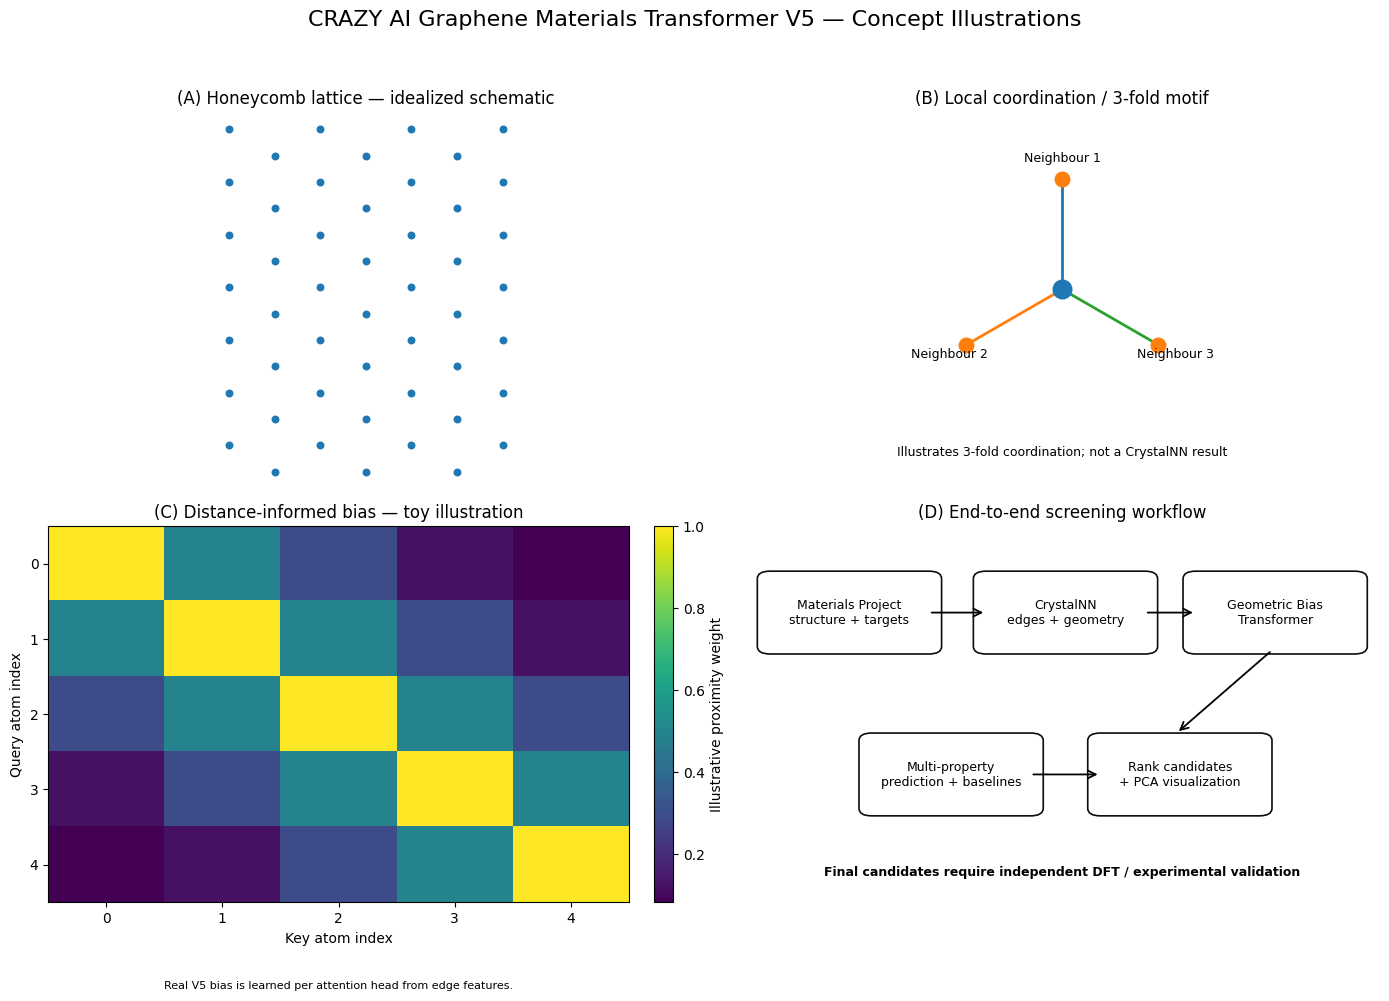

Concept illustration saved to: output/v5_concept_illustrations.png
Reminder: the figure is schematic, not an actual structure or model prediction.


In [3]:
# [셀의 목적]
# 이 셀은 연구 개념을 설명하기 위한 4개 패널의 모식도를 생성합니다.
# 그림은 이상화된 벌집 격자, 3배위 개념, 장난감 기하 Bias 행렬, 전체 파이프라인을 나타냅니다.
# Matplotlib의 좌표와 색상은 설명을 위한 인위적 값이며 Materials Project에서 가져온 실측 구조가 아닙니다.
# 따라서 이 그림을 실제 후보 물질의 원자 좌표, 학습된 Attention 가중치 또는 예측 결과로 해석하면 안 됩니다.
# plt.subplots는 2×2 도화지를 만들고 각 axes에 서로 다른 개념도를 그립니다.
# fig.savefig를 사용하면 노트북을 실행한 작업 폴더의 output 폴더에 PNG로 저장할 수 있습니다.
# [검증 관점] 모식도는 모델의 과학적 타당성이나 예측 정확도를 입증하지 않습니다.

# 시각 자료 생성 — 모두 개념 설명용 도식이며 실제 계산 결과가 아닙니다.
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("CRAZY AI Graphene Materials Transformer V5 — Concept Illustrations", fontsize=16, y=0.99)

# (A) Ideal honeycomb lattice schematic
ax = axes[0, 0]
a = 1.0
pts = []
# Generate two interleaved triangular sublattices for a finite honeycomb-like patch
for i in range(-3, 4):
    for j in range(-3, 4):
        x = 1.5 * i
        y = np.sqrt(3) * (j + 0.5 * (i % 2))
        pts.append((x, y))
pts = np.array(pts)
# Draw nearest-neighbour schematic bonds, avoiding repeated pairs
for i, (x1, y1) in enumerate(pts):
    for j in range(i + 1, len(pts)):
        x2, y2 = pts[j]
        d = np.hypot(x2-x1, y2-y1)
        if 0.95 < d < 1.05:
            ax.plot([x1, x2], [y1, y2], linewidth=1.2, alpha=0.8)
ax.scatter(pts[:, 0], pts[:, 1], s=22, zorder=3)
ax.set_title("(A) Honeycomb lattice — idealized schematic")
ax.set_aspect("equal")
ax.axis("off")

# (B) Central site and three-coordinated local-neighbour schematic
ax = axes[0, 1]
center = np.array([0.0, 0.0])
angles = np.deg2rad([90, 210, 330])
neighbors = np.c_[np.cos(angles), np.sin(angles)]
for p in neighbors:
    ax.plot([center[0], p[0]], [center[1], p[1]], linewidth=2)
ax.scatter([0], [0], s=180, zorder=3, label="Central atom")
ax.scatter(neighbors[:, 0], neighbors[:, 1], s=110, zorder=3, label="Three neighbours")
for k, p in enumerate(neighbors, start=1):
    ax.text(p[0]*1.18, p[1]*1.18, f"Neighbour {k}", ha="center", va="center", fontsize=9)
ax.text(0, -1.5, "Illustrates 3-fold coordination; not a CrystalNN result", ha="center", fontsize=9)
ax.set_title("(B) Local coordination / 3-fold motif")
ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.6)
ax.set_aspect("equal"); ax.axis("off")

# (C) Geometric bias illustration from pairwise distances (toy values)
ax = axes[1, 0]
dist = np.array([[0.0, 1.42, 2.46, 4.2, 5.0],
                 [1.42, 0.0, 1.42, 2.46, 4.2],
                 [2.46, 1.42, 0.0, 1.42, 2.46],
                 [4.2, 2.46, 1.42, 0.0, 1.42],
                 [5.0, 4.2, 2.46, 1.42, 0.0]])
# A toy monotonic distance-dependent illustration, not the learned neural bias
toy_bias = np.exp(-dist / 2.0)
im = ax.imshow(toy_bias, aspect="auto")
ax.set_title("(C) Distance-informed bias — toy illustration")
ax.set_xlabel("Key atom index"); ax.set_ylabel("Query atom index")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Illustrative proximity weight")
ax.text(0.5, -0.23, "Real V5 bias is learned per attention head from edge features.",
        transform=ax.transAxes, ha="center", fontsize=8)

# (D) Research pipeline schematic
ax = axes[1, 1]
ax.set_title("(D) End-to-end screening workflow")
ax.axis("off")
boxes = [
    (0.04, 0.68, 0.25, 0.18, "Materials Project\nstructure + targets"),
    (0.38, 0.68, 0.25, 0.18, "CrystalNN\nedges + geometry"),
    (0.71, 0.68, 0.25, 0.18, "Geometric Bias\nTransformer"),
    (0.20, 0.25, 0.25, 0.18, "Multi-property\nprediction + baselines"),
    (0.56, 0.25, 0.25, 0.18, "Rank candidates\n+ PCA visualization"),
]
for x, y, w, h, label in boxes:
    patch = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02",
                           linewidth=1.2, facecolor="white", alpha=0.95)
    ax.add_patch(patch)
    ax.text(x+w/2, y+h/2, label, ha="center", va="center", fontsize=9)
arrows = [((0.29,0.77),(0.38,0.77)), ((0.63,0.77),(0.71,0.77)),
          ((0.83,0.67),(0.68,0.45)), ((0.45,0.34),(0.56,0.34))]
for start, end in arrows:
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="->", mutation_scale=14, linewidth=1.3))
ax.text(0.5, 0.08, "Final candidates require independent DFT / experimental validation",
        ha="center", va="center", fontsize=9, weight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

plt.tight_layout(rect=[0, 0, 1, 0.96])
figure_path = os.path.join(OUTPUT_DIR, "v5_concept_illustrations.png")
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print("Concept illustration saved to:", figure_path)
print("Reminder: the figure is schematic, not an actual structure or model prediction.")


In [4]:
# [셀의 목적]
# Materials Project API 키를 코드에 직접 적지 않고 안전한 설정 저장소에서 읽어옵니다.
# Colab에서는 좌측의 Secrets 기능에 MP_API_KEY 이름으로 비밀 값을 등록합니다.
# Colab이 아닌 환경에서는 운영체제 환경 변수 MP_API_KEY를 읽도록 대체 경로를 둡니다.
# try/except는 Colab 전용 모듈을 사용할 수 없는 로컬 환경에서도 실행 경로를 선택하게 합니다.
# 키 값 자체는 출력하지 않고 로드 성공 여부만 알려 비밀 정보 노출을 줄입니다.
# 키가 비어 있으면 이후 API 요청이 실패하는 대신 명확한 ValueError를 발생시킵니다.
# [보안] 키를 노트북에 평문으로 저장하거나 공개 저장소에 업로드하지 마십시오.
# 이미 노출된 키가 있다면 Materials Project 계정에서 폐기/재발급하는 것이 안전합니다.

# 2. Materials Project API 키 설정 — 보안 가이드 준수
# Colab 환경의 경우, 보안 강화를 위해 좌측 열쇠 아이콘(Secrets)에 'MP_API_KEY' 변수명으로 키 값을 등록하십시오.
# 로컬 터미널 환경에서는 export MP_API_KEY="your_key_here" 명령으로 미리 세팅해 두어야 에러 없이 동작합니다.
import os
try:
    from google.colab import userdata
    MP_API_KEY = userdata.get("MP_API_KEY")
except Exception:
    MP_API_KEY = os.environ.get("MP_API_KEY", "")

if not MP_API_KEY:
    raise ValueError("MP_API_KEY를 찾을 수 없습니다. 비밀 관리자(Secrets) 또는 환경 변수를 통해 입력했는지 확인하십시오.")

print("Materials Project API 키 로드 성공 (키 값 노출 생략).")

Materials Project API 키 로드 성공 (키 값 노출 생략).


In [5]:
# [셀의 목적]
# Materials Project에서 화학 조성, 밴드갭, 형성 에너지, hull 거리, 결정 구조를 조회합니다.
# load_materials_project_data_v5 함수는 조회 조건을 인자로 받아 재사용할 수 있게 구성되어 있습니다.
# max_samples는 가져올 최대 자료 수, min/max_elements는 화합물의 원소 종류 수 범위입니다.
# max_eah는 energy above hull의 검색 상한(eV/atom)이며, 여기서는 낮은 hull 거리의 후보를 우선 조회합니다.
# fields는 API에서 요청할 필드 목록입니다. 불필요한 필드를 줄이면 전송량을 줄일 수 있습니다.
# 실제 구조가 있으면 Structure의 사이트 순서를 그대로 보존해 원자번호 목록을 만듭니다.
# 이 순서 보존은 이후 edge_index의 원자 인덱스와 Transformer 토큰 인덱스를 맞추는 데 중요합니다.
# 구조가 없는 경우 조성에서 원자번호를 근사 목록으로 만들지만, 이 경우 실제 기하학적 구조 정보는 없습니다.
# formation_energy는 원자당 형성 에너지, band_gap은 밴드갭, energy_above_hull은 hull 위 에너지입니다.
# 조회 결과가 비어 있으면 원인을 확인할 수 있도록 예외를 발생시킵니다.
# 마지막에는 원본 조회 결과를 CSV로 저장해 후속 셀에서 재사용할 수 있게 합니다.
# [주의] API 응답과 필드 가용성은 데이터베이스 버전·권한·요청 조건에 따라 달라질 수 있습니다.

# 3. Materials Project 데이터 다운로드 — 실제 구조 사이트 순서 보존
from mp_api.client import MPRester
from pymatgen.core import Structure

def load_materials_project_data_v5(api_key, max_samples=MAX_SAMPLES,
                                   min_elements=1, max_elements=6, max_eah=0.1,
                                   max_atoms=16):
    """
    주어진 조건에 부합하는 무기 화합물을 Materials Project로부터 일괄 다운로드
    """
    # API 요청을 시작한다. 실제 데이터 수와 응답은 API 상태 및 검색 조건에 따라 달라진다.
    print('[1] Materials Project 데이터셋 다운로드 시작...')
    fields = ['material_id','formula_pretty','composition','band_gap',
              'formation_energy_per_atom','energy_above_hull','is_stable','structure']
    records = []

    with MPRester(api_key) as mpr:
        # 에너지 조건(E_hull <= 0.1 eV/atom) 및 안정 구조물(is_stable) 필터링 검색
        docs = mpr.materials.summary.search(
            num_elements=(min_elements, max_elements),
            energy_above_hull=(0., max_eah), is_stable=True, fields=fields)

        # 조회된 문서를 한 건씩 처리하며 max_samples에 도달하면 반복을 멈춘다.
        for doc in docs:
            if len(records) >= max_samples:
                break
            structure = doc.structure

            # 결정 구조(Structure) 정보가 유효한 경우 사이트의 순서대로 정적 정렬 유지
            if structure is not None and len(structure) > 0:
                atoms = [int(site.specie.Z) for site in structure[:max_atoms]]
                structure_dict = structure.as_dict()
                n_sites_raw = len(structure)
            else:
                # 비구조적 폴백 처리: 화학 조성비를 기준으로 정밀 변환 수행
                atoms = []
                for el, amt in doc.composition.items():
                    atoms.extend([int(el.Z)] * max(1, int(round(float(amt)))))
                atoms = atoms[:max_atoms]
                structure_dict, n_sites_raw = None, 0

            if not atoms:
                continue

            # API 문서의 물성·조성·구조를 일관된 딕셔너리 형태로 기록한다.
            records.append({
                'material_id': str(doc.material_id),
                'formula': doc.formula_pretty,
                'atomic_numbers': atoms,
                'band_gap': float(doc.band_gap) if doc.band_gap is not None else np.nan,
                'formation_energy': float(doc.formation_energy_per_atom) if doc.formation_energy_per_atom is not None else np.nan,
                'energy_above_hull': float(doc.energy_above_hull) if doc.energy_above_hull is not None else np.nan,
                'is_stable': bool(doc.is_stable),
                'has_structure': structure is not None,
                'n_sites_raw': n_sites_raw,
                'structure_dict': structure_dict
            })

    df_out = pd.DataFrame(records)
    if df_out.empty:
        raise RuntimeError('Materials Project 조회 결과가 비어있습니다. API 설정 또는 쿼리 한계를 검토하세요.')
    print(f'다운로드 완료: {len(df_out):,} 건 | 구조 데이터 포함: {int(df_out["has_structure"].sum()):,} 건')
    return df_out

df_raw = load_materials_project_data_v5(MP_API_KEY)
df_raw.to_csv(os.path.join(OUTPUT_DIR, 'materials_project_raw_v5.csv'), index=False)

[1] Materials Project 데이터셋 다운로드 시작...


Output()

✓ Retrieved 32,534 SummaryDoc documents in 123.2s

다운로드 완료: 500 건 | 구조 데이터 포함: 500 건


In [6]:
# [셀의 목적]
# 원시 API 자료를 정리하고 원자 조성에서 기본적인 수치형 descriptor를 계산합니다.
# TARGET_COLS는 모델이 예측할 세 가지 목표값을 정의합니다.
# clean_atomic_numbers는 원자번호 목록에서 정수로 변환할 수 있고 1~118 범위인 값만 남깁니다.
# composition_features는 원자 수, 원자번호 평균/표준편차, 탄소 비율, 14족 원소 비율 등을 계산합니다.
# carbon_ratio는 잘라낸 원자 목록 중 탄소 원자가 차지하는 비율입니다.
# group14_ratio는 C, Si, Ge, Sn의 비율을 합산한 간단한 조성 지표입니다.
# metal_ratio는 미리 정의한 NONMETAL_Z 집합에 속하지 않는 원소를 금속으로 간주한 근사 비율입니다.
# 이 금속/비금속 분류는 간단한 휴리스틱이므로 정밀한 화학 분류로 해석하면 안 됩니다.
# preprocess_materials_df는 중복 material_id와 타깃 결측치를 제거하고 원자번호 목록을 정리합니다.
# 이상치 제거는 기본적으로 꺼져 있어 희귀 물질을 자동으로 제거하지 않습니다.
# max_atoms 제한은 모델 입력 길이를 고정 범위로 유지하지만, 큰 셀의 일부 원자를 잘라낼 수 있습니다.
# [중요] 원자 목록을 자르면 조성 비율은 전체 결정의 정확한 화학량론과 달라질 수 있으므로 결과 해석에 주의합니다.

# 4. 기본 전처리 — 안전한 조성 피처 계산 및 필터링
TARGET_COLS = ['formation_energy', 'band_gap', 'energy_above_hull']
NONMETAL_Z = {1,2,5,6,7,8,9,10,15,16,34,52}

 # 입력값의 자료형이 예상과 다르거나 원자번호 범위를 벗어나면 제외한다.
def clean_atomic_numbers(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        out=[]
        for z in x:
            try:
                zi=int(z)
                if 1 <= zi <= 118: out.append(zi)
            except (TypeError, ValueError):
                continue
        return out
    return []

 # 원자번호 목록에서 모델에 넣을 수 있는 조성 요약 통계량을 계산한다.
def composition_features(atoms):
    c=Counter(atoms); n=len(atoms)
    if n == 0:
        return pd.Series({'n_atoms':0,'z_mean':0.,'z_std':0.,'carbon_ratio':0.,
                          'group14_ratio':0.,'metal_ratio':0.,'n_unique_elements':0})
    return pd.Series({'n_atoms':n,'z_mean':float(np.mean(atoms)),
        'z_std':float(np.std(atoms)) if n>1 else 0., 'carbon_ratio':c.get(6,0)/n,
        'group14_ratio':sum(c.get(z,0) for z in (6,14,32,50))/n,
        'metal_ratio':sum(v for z,v in c.items() if z not in NONMETAL_Z)/n,
        'n_unique_elements':len(c)})

 # 원본을 복사한 뒤 중복·결측·잘못된 원자 목록을 순서대로 정리한다.
def preprocess_materials_df(data, max_atoms=16, remove_outliers=False, iqr_factor=3.):
    data=data.copy(); initial=len(data)
    data=data.drop_duplicates(subset=['material_id'], keep='first')
    data=data.dropna(subset=TARGET_COLS)
    data['atomic_numbers']=data['atomic_numbers'].apply(clean_atomic_numbers)
    data=data[data['atomic_numbers'].apply(len)>0].copy()
    # 기본값은 이상치 제거 OFF: 희귀 물질을 임의로 제거하지 않음.
    # 필요 시 탐색적 분석으로 제외 목록을 기록한 뒤 별도 적용하세요.
    if remove_outliers:
        before=len(data)
        for col in TARGET_COLS:
            q1,q3=data[col].quantile(.25),data[col].quantile(.75); iqr=q3-q1
            if pd.notna(iqr) and iqr>0:
                data=data[data[col].between(q1-iqr_factor*iqr,q3+iqr_factor*iqr)]
        print(f'Outliers removed by optional IQR filter: {before-len(data)}')
    data['atomic_numbers']=data['atomic_numbers'].apply(lambda x:x[:max_atoms])
    features=data['atomic_numbers'].apply(composition_features)
    data=pd.concat([data,features],axis=1)
    print(f'Initial: {initial}, Final: {len(data)}, Shape: {data.shape}')
    return data

df = preprocess_materials_df(df_raw, remove_outliers=False)


Initial: 500, Final: 500, Shape: (500, 17)


## 구조 피처 + Edge 추출이 Transformer에 미치는 영향

이 단계에서 **CrystalNN**으로 원자 간 결합을 찾아 `edge_index`(연결)와 `edge_attr`(결합 길이)를 만든다.

### Transformer와의 연결
- 표준 Transformer Self-Attention은 **모든 원자 쌍**에 대해 동일한 방식으로 점수를 계산한다.
- ComFormer 스타일에서는 **실제 결합이 있는 원자 쌍**에 대해 결합 길이를 Attention Score에 **Bias**로 더한다.
- 즉, 가까운 원자(짧은 결합)와 먼 원자를 Attention이 다르게 취급할 수 있게 된다.

```
Attention Score = (Q K^T) / sqrt(d_k)  +  Geometric_Bias(결합길이)
```

`edge_dict[material_id] = (edge_index, edge_attr)` 형태로 저장되며,
모델 `forward`의 선택 인자로 전달될 수 있다. (현재 학습 루프에서는 배치 단순화로 mask만 사용하고,
구조는 기하 Bias 인프라를 갖춘 상태로 준비된다.)

In [7]:
# [셀의 목적]
# 결정 구조를 pymatgen으로 복원하고 CrystalNN으로 각 원자의 국소 이웃을 탐색합니다.
# CrystalNN은 원자 주변의 국소 환경을 바탕으로 이웃 후보를 판단하는 알고리즘입니다.
# edge_index는 원자 쌍의 연결 인덱스이며 보통 (2, E) 배열로 저장합니다.
# edge_attr에는 각 간선에 대응하는 원자 사이 거리(Å)를 저장합니다.
# edge_dict는 material_id를 키로 하여 해당 재료의 edge_index와 edge_attr를 보관합니다.
# 구조가 없거나 파싱에 실패하면 기본 descriptor와 빈 edge 목록을 반환해 파이프라인 중단을 줄입니다.
# 배위수는 CrystalNN이 반환한 이웃 수로 근사하며, 모든 물질에서 화학적 결합을 완벽히 판별한다는 뜻은 아닙니다.
# 3배위 분율과 탄소 중심 3배위 분율은 sp² 유사 환경을 탐색하는 지표이지 혼성화 상태의 직접 측정값은 아닙니다.
# 결합각 편차는 탄소 주변 각도가 이상적 120°에서 얼마나 떨어지는지 평균 절댓값으로 계산합니다.
# C–C 거리 편차는 1.42 Å를 그래핀의 대표 기준값으로 둔 휴리스틱입니다.
# get_dimensionality 실패 시 0을 넣으므로 0은 실제 0차원 구조와 분석 실패를 구분하지 못할 수 있습니다.
# 마지막에는 구조 descriptor를 material_id로 df에 병합하고 CSV로 저장합니다.
# [주의] CrystalNN의 이웃 판정은 설정·구조 품질에 민감하며, 모서리/주기 경계/큰 셀의 해석을 확인해야 합니다.

# 5. 구조 피처 + Edge 정보 추출 (기하 Bias 연산 준비)
from pymatgen.core import Structure
from pymatgen.analysis.local_env import CrystalNN
import warnings

 # 구조 딕셔너리 하나를 받아 통계 descriptor와 모델용 간선 배열을 함께 만든다.
def extract_structure_and_edges(structure_dict, max_neighbors=8, max_atoms=16):
    """
    Pymatgen 구조 딕셔너리로부터 Local Environment를 재구성하여
    CrystalNN 기반의 배위수 분석 및 기하학적 인접 간선(Edges) 정보 도출
    """
    # 3D 구조 분석 실패 시 활용할 기본값 및 대체 통계 사전 정의
    default_feat = {
        'n_sites':0, 'mean_coordination_number':0., 'std_coordination_number':0.,
        'mean_bond_length':0., 'std_bond_length':0., 'mean_bond_angle':0.,
        'std_bond_angle':0., 'estimated_dimensionality':0,
        'carbon_fraction':0., 'three_coordinate_fraction':0., 'carbon_three_coordinate_fraction':0.,
        'carbon_three_coordinate_count':0, 'carbon_sp2_angle_deviation':60.,
        'cc_bond_length_deviation':1.
    }
    empty_edge = (np.zeros((2,0), dtype=np.int64), np.zeros((0,1), dtype=np.float32))

    if structure_dict is None:
        return default_feat, empty_edge
    try:
        structure = Structure.from_dict(structure_dict)
    except:
        return default_feat, empty_edge

    n_sites = min(len(structure), max_atoms)
    # 구조 내부의 탄소 원자 위치(인덱스) 수집
    carbon_indices = [i for i,s in enumerate(structure) if s.specie.Z==6 and i < n_sites]
    carbon_fraction = len(carbon_indices)/n_sites if n_sites else 0.

    try:
        cnn = CrystalNN()
        coords, bonds, angles, carbon_angles, three_coord, carbon_three_coord, cc_bonds = [], [], [], [], 0, 0, []
        edge_src, edge_dst, edge_len = [], [], []

        # 원자별로 가장 유효한 최근접 결합 이웃 파악
        # 구조의 앞쪽 n_sites개 원자를 중심 원자로 삼아 국소 환경을 탐색한다.
        for i in range(n_sites):
            try:
                neighbors = cnn.get_nn_info(structure, i)[:max_neighbors]
            except:
                continue
            coords.append(len(neighbors))
            # 3배위 배치가 확인된 경우, sp2 도메인 분석 후보로 가중치 적용
            if len(neighbors) == 3:
                three_coord += 1
                if structure[i].specie.Z == 6:
                    carbon_three_coord += 1

            # 각 이웃 원자와의 실제 결합 길이 연산
            for nb in neighbors:
                j = nb['site_index']
                if j >= n_sites: continue
                try:
                    d = structure.get_distance(i, j)
                    bonds.append(d)
                    # 기하학적 Attention Bias 매트릭스를 생성하기 위한 원본 및 목적 노드 인덱스 매핑
                    edge_src.append(i); edge_dst.append(j); edge_len.append(d)
                    # 탄소 원자끼리(C-C) 인접한 결합 거리만 추출
                    if structure[i].specie.Z==6 and structure[j].specie.Z==6:
                        cc_bonds.append(d)
                except:
                    continue

            # 중심 원자의 주변 원소 각도를 연산하여 120°(sp2 결합각 모델 기준)에서의 편차 파악
            valid_neighbor_ids = [nb['site_index'] for nb in neighbors if nb['site_index'] < n_sites]
            if len(valid_neighbor_ids) >= 2:
                for a in range(len(valid_neighbor_ids)):
                    for b in range(a+1, len(valid_neighbor_ids)):
                        try:
                            angle = float(structure.get_angle(valid_neighbor_ids[a], i, valid_neighbor_ids[b]))
                            angles.append(angle)
                            if structure[i].specie.Z == 6:
                                carbon_angles.append(angle)
                        except Exception:
                            continue
        try:
            # 물질의 결정 구조 차원성 추론
            from pymatgen.analysis.dimensionality import get_dimensionality
            dimensionality = get_dimensionality(structure)
        except:
            dimensionality = 0

        # 실측 C-C 거리가 이상적 그래핀의 1.42 Å 분산 기준치에서 얼마나 떨어졌는지 검토
        cc_dev = float(np.mean(np.abs(np.array(cc_bonds)-1.42))) if cc_bonds else 1.
        # 모델 외부의 후보 필터링/해석에 사용할 구조 통계량을 하나의 사전으로 묶는다.
        feat = {
            'n_sites': n_sites,
            'mean_coordination_number': float(np.mean(coords)) if coords else 0.,
            'std_coordination_number': float(np.std(coords)) if len(coords)>1 else 0.,
            'mean_bond_length': float(np.mean(bonds)) if bonds else 0.,
            'std_bond_length': float(np.std(bonds)) if len(bonds)>1 else 0.,
            'mean_bond_angle': float(np.mean(angles)) if angles else 0.,
            'std_bond_angle': float(np.std(angles)) if len(angles)>1 else 0.,
            'estimated_dimensionality': int(dimensionality),
            'carbon_fraction': float(carbon_fraction),
            'three_coordinate_fraction': float(three_coord/n_sites) if n_sites else 0.,
            'carbon_three_coordinate_count': int(carbon_three_coord),
            'carbon_three_coordinate_fraction': float(carbon_three_coord/len(carbon_indices)) if carbon_indices else 0.,
            'carbon_sp2_angle_deviation': float(np.mean(np.abs(np.asarray(carbon_angles)-120.0))) if carbon_angles else 60.,
            'cc_bond_length_deviation': cc_dev
        }
        if edge_src:
            # 모델 순전파에 쓰일 실제 간선 및 차원 축소 맵 정리
            edge_index = np.array([edge_src, edge_dst], dtype=np.int64)
            edge_attr = np.array(edge_len, dtype=np.float32).reshape(-1, 1)
        else:
            edge_index, edge_attr = empty_edge
        return feat, (edge_index, edge_attr)
    except:
        return default_feat, empty_edge

print('[2] 각 결정 구조별 원자 배위구조 분석 및 그래프 Edges 정보 추출 중 (일부 수 분 소요)...')
structure_rows = []
edge_dict = {}
 # 각 물질의 구조를 개별 처리해 material_id와 간선 목록을 연결한다.
for _, row in df_raw.iterrows():
    feat, (eidx, eattr) = extract_structure_and_edges(row.get('structure_dict', None))
    feat['material_id'] = row['material_id']
    structure_rows.append(feat)
    edge_dict[row['material_id']] = (eidx, eattr)

# 전처리 완료된 데이터프레임과 기하학적 통계치를 아이디 기준으로 조인(Join) 병합
structure_features_df = pd.DataFrame(structure_rows)
df = df.merge(structure_features_df, on='material_id', how='left', suffixes=('', '_structure'))
STRUCTURE_FEATURE_COLS = [
    'n_sites','mean_coordination_number','std_coordination_number',
    'mean_bond_length','std_bond_length','mean_bond_angle','std_bond_angle',
    'estimated_dimensionality','carbon_fraction','three_coordinate_fraction',
    'carbon_three_coordinate_fraction','carbon_three_coordinate_count','carbon_sp2_angle_deviation',
    'cc_bond_length_deviation'
]
for col in STRUCTURE_FEATURE_COLS:
    if col in df.columns:
        df[col] = df[col].fillna(0.)

df.to_csv(os.path.join(OUTPUT_DIR, 'materials_with_structure_features_v5.csv'), index=False)
print('결정 기하구조 특징 추출 및 가중 간선 테이블 정렬 완료.')
print(df[STRUCTURE_FEATURE_COLS].describe().T)

[2] 각 결정 구조별 원자 배위구조 분석 및 그래프 Edges 정보 추출 중 (일부 수 분 소요)...
결정 기하구조 특징 추출 및 가중 간선 테이블 정렬 완료.
                                  count       mean        std       min  \
n_sites                           500.0  11.256000   5.218902  1.000000   
mean_coordination_number          500.0   4.985469   2.000497  1.500000   
std_coordination_number           500.0   0.876194   0.794433  0.000000   
mean_bond_length                  500.0   2.023477   1.084822  0.000000   
std_bond_length                   500.0   0.113242   0.180507  0.000000   
mean_bond_angle                   500.0  46.573904  30.851100  0.000000   
std_bond_angle                    500.0  31.853514  25.069125  0.000000   
estimated_dimensionality          500.0   0.000000   0.000000  0.000000   
carbon_fraction                   500.0   0.003090   0.030540  0.000000   
three_coordinate_fraction         500.0   0.105548   0.196159  0.000000   
carbon_three_coordinate_fraction  500.0   0.002000   0.044721  0.000000   
carbon_t

In [8]:
# [셀의 목적]
# 데이터 누수를 줄이기 위해 train, validation, test 세 부분으로 데이터를 분리합니다.
# train은 가중치 학습에, validation은 학습 중 모델 선택/체크포인트 선택에, test는 최종 평가에 사용합니다.
# test_size와 val_size는 전체 데이터 기준 비율입니다. 코드에서는 trainval 안에서 validation 비율을 환산합니다.
# StandardScaler는 각 타깃의 평균을 0, 표준편차를 1에 가깝게 변환합니다.
# 스케일러는 train_df의 타깃값에만 fit하므로 validation/test의 통계가 학습에 섞이지 않습니다.
# 같은 스케일러로 train/validation/test 타깃을 transform해 비교 가능한 학습 목표를 만듭니다.
# 결과 데이터프레임을 copy해 원본 분할 자료에 대한 불필요한 변경을 줄입니다.
# 분할 데이터는 CSV로 저장하여 나중에 어떤 표본이 각 분할에 들어갔는지 추적할 수 있게 합니다.
# [주의] 무작위 분할은 유사 조성·구조가 서로 다른 분할에 들어갈 수 있어 일반화 성능이 낙관적으로 보일 수 있습니다.
# 후속 연구에서는 조성 계열/구조군을 묶는 group split 또는 시간·출처 기반 분할도 검토하십시오.

# 6. Train/Validation/Test 분할 + 타깃 스케일링
# 테스트셋은 모델 선택에 사용하지 않는 최종 독립 평가용입니다.
 # 세 분할을 만들고 train 데이터만으로 타깃 스케일러를 적합한다.
def make_train_val_test_split(data, test_size=.15, val_size=.15, random_state=SEED):
    trainval_df, test_df = train_test_split(data, test_size=test_size,
                                            random_state=random_state, shuffle=True)
    val_fraction_of_trainval = val_size / (1.0 - test_size)
    train_df, val_df = train_test_split(trainval_df, test_size=val_fraction_of_trainval,
                                        random_state=random_state, shuffle=True)
    # 스케일러의 평균·표준편차를 train에만 맞춰 데이터 누수를 방지한다.
    target_scaler = StandardScaler().fit(train_df[TARGET_COLS].to_numpy(dtype=np.float32))
    scaled_cols=[c+'_scaled' for c in TARGET_COLS]
    for part in (train_df, val_df, test_df):
        part[scaled_cols]=target_scaler.transform(part[TARGET_COLS].to_numpy(dtype=np.float32))
    print(f'Train: {len(train_df)}, Validation: {len(val_df)}, Test: {len(test_df)}')
    return train_df.copy(), val_df.copy(), test_df.copy(), target_scaler

train_df, val_df, test_df, target_scaler = make_train_val_test_split(df)
train_df.to_csv(os.path.join(OUTPUT_DIR,'train_df_v5.csv'),index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR,'val_df_v5.csv'),index=False)
test_df.to_csv(os.path.join(OUTPUT_DIR,'test_df_v5.csv'),index=False)


Train: 350, Validation: 75, Test: 75


## 원소 피처가 Transformer 입력에 들어가는 방식

원자번호만 임베딩하면 물리화학 정보가 부족하다.
각 원자에 대해 **9차원 물리 피처**(전기음성도, 원자반지름, 이온화에너지, 녹는점, 밀도, 원자질량, 족, 주기, 원자번호)를
계산하고 StandardScaler로 정규화한다.

### Transformer 입력 토큰 구성
```
토큰_i = Concat( AtomicEmbedding(Z_i) ,  FeatureProjection(물리피처_i) )
        → 차원: (d_model/2) + (d_model/2) = d_model (기본 128)
```

이 방식이 단순 원자번호 시퀀스보다 **재료 도메인 inductive bias**를 강하게 준다.

In [9]:
# [셀의 목적]
# 원자번호만으로 표현하기 어려운 원소의 화학적 성질을 9개 수치 피처로 보완합니다.
# 피처는 전기음성도, 원자 반지름, 이온화 에너지, 녹는점, 고체 밀도, 원자량, 족, 주기, 원자번호입니다.
# safe 함수는 속성이 None이면 지정한 대체값을 넣어 결측치로 인한 계산 실패를 줄입니다.
# 일부 원소의 속성은 pymatgen에서 정의되지 않을 수 있으므로 대체값은 실제 측정값이 아닐 수 있습니다.
# np.nan_to_num은 NaN과 무한대를 유한한 수로 바꿉니다.
# 1~118번 원소 전체로 StandardScaler를 fit해 원소 피처의 크기 차이를 완화합니다.
# 이 스케일러는 데이터셋의 타깃값이 아닌 주기율표 속성만으로 계산됩니다.
# get_element_feature_normalized는 원자별로 정규화한 9차원 벡터를 PyTorch Tensor로 반환합니다.
# 모델에서는 이 벡터를 원자번호 임베딩과 연결해 하나의 원자 토큰 표현을 만듭니다.
# [주의] 대체값과 전체 원소 범위의 표준화는 실용적 출발점이며, 도메인에 맞춘 피처 검증이 필요합니다.

# 7. 확장 원소 피처 (9차원) — Transformer 토큰의 절반을 구성
from pymatgen.core import Element

def get_extended_element_feature_vector(z):
    """원자 번호(Z)를 받아 주기율표 기본 속성을 9차원 배열로 수집"""
    e = Element.from_Z(int(z))
    def safe(v, d): return float(v) if v is not None else float(d)
    try: group = float(e.group)
    except: group = 0.
    try: period = float(e.row)
    except: period = 0.
    # 전기음성도, 원자반지름, 이온화에너지, 녹는점, 밀도, 원자량, 족, 주기, 원자번호
    return np.nan_to_num(np.array([
        safe(e.X,1.5), safe(e.atomic_radius,150.), safe(e.ionization_energy,8.),
        safe(e.melting_point,500.), safe(e.density_of_solid,5.), safe(e.atomic_mass,50.),
        group, period, float(z)
    ], dtype=np.float32), nan=0., posinf=0., neginf=0.)

# 1번 원소 수소부터 118번 오가네손까지 일괄 수집 후 정규화 스케일러 피팅
extended_matrix = np.vstack([get_extended_element_feature_vector(z) for z in range(1,119)])
extended_element_scaler = StandardScaler().fit(extended_matrix)

def get_element_feature_normalized(z):
    """정규화 과정을 적용한 원자별 9차원 화학 피처 반환"""
    raw = get_extended_element_feature_vector(int(z))
    return torch.tensor(extended_element_scaler.transform(raw.reshape(1,-1))[0], dtype=torch.float32)

N_ELEMENT_FEATURES = 9
print(f'Element feature dim: {N_ELEMENT_FEATURES}')

Element feature dim: 9


In [10]:
# [셀의 목적]
# Dataset은 재료 1개를 원자번호, 원소 피처, 타깃, 식, material_id, 간선 정보로 변환합니다.
# __getitem__은 DataLoader가 요청한 표본 하나를 반환하고 __len__은 표본 개수를 알려줍니다.
# 각 구조의 원자 사이트 순서와 edge_index 인덱스가 일치하도록 같은 원자 목록을 사용합니다.
# 원자 수가 max_len보다 크면 앞쪽 max_len개만 사용하므로, 이는 구조를 압축한 근사 입력입니다.
# collate_fn_v5는 길이가 다른 원자 목록을 배치 안에서 가장 긴 길이까지 0으로 패딩합니다.
# mask에서 False는 실제 원자, True는 패딩 위치를 의미합니다.
# edge 목록은 샘플마다 원자 인덱스의 기준이 다르므로 하나의 거대한 그래프로 합치지 않고 목록으로 유지합니다.
# DataLoader는 학습에서만 shuffle=True를 사용해 배치 순서를 섞고, 검증/테스트에서는 순서를 유지합니다.
# [주의] 타깃 스케일 컬럼이 누락된 경우 0.0으로 대체하는 코드는 오류를 숨길 수 있으므로 실제 데이터에서는 컬럼 존재를 확인해야 합니다.

# 8. Dataset & DataLoader — 구조 사이트/Edge를 배치별로 보존
 # PyTorch가 이해할 수 있도록 재료 한 건을 Tensor 중심의 샘플로 변환한다.
class RealMaterialDatasetV5(Dataset):
    def __init__(self, dataframe, edge_dict, max_len=16):
        self.samples=[]
        for _,row in dataframe.iterrows():
            atoms=list(row['atomic_numbers'])[:max_len]
            if not atoms: continue
            feats=torch.stack([get_element_feature_normalized(z) for z in atoms])
            vals=[row.get(c+'_scaled',0.0) for c in TARGET_COLS]
            target=torch.tensor([float(v) if pd.notna(v) else 0.0 for v in vals],dtype=torch.float32)
            eidx,eattr=edge_dict.get(row['material_id'],
                (np.zeros((2,0),dtype=np.int64),np.zeros((0,1),dtype=np.float32)))
            eidx=np.asarray(eidx,dtype=np.int64); eattr=np.asarray(eattr,dtype=np.float32).reshape(-1,1)
            if eidx.shape[1]:
                valid=(eidx[0]>=0)&(eidx[1]>=0)&(eidx[0]<len(atoms))&(eidx[1]<len(atoms))
                eidx,eattr=eidx[:,valid],eattr[valid]
            self.samples.append((torch.tensor(atoms,dtype=torch.long),feats,target,
                str(row['formula']),str(row['material_id']),torch.tensor(eidx,dtype=torch.long),
                torch.tensor(eattr,dtype=torch.float32)))
        print(f'Dataset size: {len(self.samples)}')
    def __len__(self): return len(self.samples)
    def __getitem__(self,idx): return self.samples[idx]

 # 서로 길이가 다른 재료를 하나의 배치로 묶고 패딩 마스크와 간선 목록을 만든다.
def collate_fn_v5(batch):
    atoms_list,feats_list,targets,formulas,mids,eidx_list,eattr_list=zip(*batch)
    max_len=max(a.size(0) for a in atoms_list); B=len(batch)
    pa=torch.zeros(B,max_len,dtype=torch.long)
    pf=torch.zeros(B,max_len,N_ELEMENT_FEATURES)
    mask=torch.ones(B,max_len,dtype=torch.bool)
    for i,(a,f) in enumerate(zip(atoms_list,feats_list)):
        L=a.size(0); pa[i,:L]=a; pf[i,:L]=f; mask[i,:L]=False
    # Edge 인덱스는 각 샘플 내부 좌표이므로 batch별 목록으로 전달
    edges=[(ei,ea) for ei,ea in zip(eidx_list,eattr_list)]
    return pa,pf,torch.stack(targets),formulas,mask,mids,edges

train_dataset=RealMaterialDatasetV5(train_df,edge_dict)
val_dataset=RealMaterialDatasetV5(val_df,edge_dict)
test_dataset=RealMaterialDatasetV5(test_df,edge_dict)
train_loader=DataLoader(train_dataset,batch_size=16,shuffle=True,collate_fn=collate_fn_v5)
val_loader=DataLoader(val_dataset,batch_size=16,shuffle=False,collate_fn=collate_fn_v5)
test_loader=DataLoader(test_dataset,batch_size=16,shuffle=False,collate_fn=collate_fn_v5)


Dataset size: 350
Dataset size: 75
Dataset size: 75


# MaterialsTransformerV5 — Transformer 아키텍처 완전 해부

이 셀에서 정의하는 모델이 노트북의 **핵심 Transformer**이다.

## 1. 전체 데이터 흐름

```
atoms (B, L)          원자번호 시퀀스
feats (B, L, 9)       원소 물리 피처
        │
        ▼
┌─────────────────────────────────────┐
│ AtomicEmbedding(Z) → (B,L,64)       │
│ FeatureProjection(feats) → (B,L,64) │
│ Concat → x (B, L, 128)              │  ← 토큰 표현
└─────────────────────────────────────┘
        │
        ▼  × 4 layers
┌─────────────────────────────────────┐
│ ComFormerEncoderLayer (Pre-LN)      │
│  1) LayerNorm                       │
│  2) GeometricBias Multi-Head Attn   │  ← Self-Attention + 선택적 거리 Bias
│  3) Residual                        │
│  4) LayerNorm + FFN(GELU) + Residual│
└─────────────────────────────────────┘
        │
        ▼
┌─────────────────────────────────────┐
│ Attention Pooling                   │
│  score_i = w·h_i → softmax → 가중합 │  ← 가변 길이 → 고정 벡터 (B, 128)
│ Final LayerNorm                     │
└─────────────────────────────────────┘
        │
        ▼
┌─────────────────────────────────────┐
│ Multi-task Heads (독립 3개)         │
│  formation_energy / band_gap / Ehull│
└─────────────────────────────────────┘
```

## 2. Scaled Dot-Product Attention (이 모델 내부)

$$
\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + B_{\mathrm{geo}}\right) V
$$

- $B_{\mathrm{geo}}$: 결합 길이를 head별 bias로 변환한 값 (edge가 있을 때만)
- Padding 위치는 `-inf`로 마스킹 후 softmax → 가중치 0

## 3. Pre-LN vs Post-LN

원 논문 Transformer는 Post-LN이지만, 이 모델은 **Pre-LN** (`norm_first` 스타일)을 사용한다.
Residual 전에 정규화하여 깊은 스택에서도 학습이 안정적이다.

## 4. Attention Pooling

BERT의 [CLS] 대신 **학습 가능한 Attention Pooling**을 사용한다.

$$
\alpha_i = \frac{\exp(w^\top h_i)}{\sum_j \exp(w^\top h_j)}, \quad z = \sum_i \alpha_i h_i
$$

모델이 “어떤 원자에 집중할지”를 스스로 학습한다 (탄소·3배위 원자 등에 가중치가 갈 수 있음).

## 5. V4 대비 변경점

| 항목 | V4 | V5 |
|------|----|----|
| d_model | 64 | **128** |
| depth | 3 | **4** |
| Attention | 표준 MHA | **Geometric Bias MHA** |
| Edge 입력 | 없음 | **edge_index / edge_attr 지원** |
| Norm | Pre-LN | Pre-LN 유지 |

In [11]:
# [셀의 목적]
# 이 셀은 결정 구조의 간선 거리 정보를 Attention Score에 더하는 Transformer를 정의합니다.
# Multi-head Attention은 Query/Key의 내적 점수를 계산하고, Value를 가중합해 원자 표현을 갱신합니다.
# GeometricBiasMultiheadAttention은 edge_attr의 결합 길이를 학습 가능한 선형층으로 투영해 head별 bias로 만듭니다.
# Attention 점수의 개념식은 QKᵀ/√d_k + geometric_bias 입니다.
# edge_index는 source/destination 원자 인덱스, edge_attr는 그 쌍의 거리값입니다.
# 거리값은 0~10 Å로 자르고 3으로 나눠 입력 크기를 제한합니다. 이는 물리 단위 변환이 아니라 안정화를 위한 휴리스틱입니다.
# 간선이 없는 쌍의 bias는 0으로 남으며, 간선이 여러 번 기록되면 평균을 내도록 카운트를 사용합니다.
# key_padding_mask는 패딩 토큰을 Key 위치에서 제외해 유효하지 않은 원자가 attention에 기여하지 않게 합니다.
# ComFormerEncoderLayer는 Pre-LayerNorm, Attention 잔차 연결, FFN 잔차 연결로 구성됩니다.
# MaterialsTransformerV5는 원자번호 임베딩과 9차원 원소 피처 투영을 이어 붙여 d_model 차원의 토큰을 만듭니다.
# 여러 Encoder Layer를 통과한 후 attention pooling으로 원자별 표현을 재료 전체의 고정 길이 벡터로 압축합니다.
# 세 개의 별도 prediction head가 형성 에너지, 밴드갭, hull 위 에너지를 동시에 예측합니다.
# [중요한 한계] 이 모델은 ComFormer의 개념을 참고한 자체 구현이며 공식 ComFormer 구현과 동일하다고 단정할 수 없습니다.
# [중요한 검증] 입력 edge와 토큰 인덱스 정합성, 패딩 마스크, 물성 단위, 학습/테스트 분리를 별도로 점검해야 합니다.

# 9. MaterialsTransformerV5 — 실제 배치별 Geometric Bias를 Attention에 반영
 # 표준 Attention 점수에 원자 간 거리에서 계산한 학습 가능한 bias를 더한다.
class GeometricBiasMultiheadAttention(nn.Module):
    """입력받은 결합 거리 데이터를 통하여 Attention 메트릭 상의 원자 간 관계 가중치를 주입합니다."""
    def __init__(self,d_model,nhead,dropout=0.1,edge_dim=1):
        super().__init__()
        assert d_model % nhead == 0
        self.d_model=d_model; self.nhead=nhead; self.head_dim=d_model//nhead
        # Query, Key, Value 프로젝션 정의
        self.q_proj=nn.Linear(d_model,d_model); self.k_proj=nn.Linear(d_model,d_model)
        self.v_proj=nn.Linear(d_model,d_model); self.out_proj=nn.Linear(d_model,d_model)
        # Edge 거리 값을 헤드별 가중치 바이어스 분포로 학습 가능한 선형 사영계 정의
        self.edge_bias_proj=nn.Sequential(nn.Linear(edge_dim,nhead),nn.Tanh())
        self.dropout=nn.Dropout(dropout); self.scale=1.0/math.sqrt(self.head_dim)

    # x의 형상은 (배치 크기, 원자 토큰 길이, 모델 차원)이다.
    def forward(self,x,key_padding_mask=None,edges=None):
        B,L,_=x.shape
        q=self.q_proj(x).view(B,L,self.nhead,self.head_dim).transpose(1,2)
        k=self.k_proj(x).view(B,L,self.nhead,self.head_dim).transpose(1,2)
        v=self.v_proj(x).view(B,L,self.nhead,self.head_dim).transpose(1,2)
        scores=torch.matmul(q,k.transpose(-2,-1))*self.scale

        if edges is not None:
            geo_bias=x.new_zeros(B,self.nhead,L,L)
            for b,(edge_index,edge_attr) in enumerate(edges):
                if edge_index.numel()==0 or edge_attr.numel()==0: continue
                edge_index=edge_index.to(x.device); edge_attr=edge_attr.to(x.device)
                src,dst=edge_index[0],edge_index[1]
                valid=(src>=0)&(dst>=0)&(src<L)&(dst<L)
                if not torch.any(valid): continue
                src,dst=src[valid],dst[valid]
                # 학습 안정성(Gradient Explosion 방지)을 위해 3.0 scale 단위 압축 정규화 적용
                dist=edge_attr[valid].clamp(min=0.0,max=10.0)/3.0
                bias=self.edge_bias_proj(dist)

                for h in range(self.nhead):
                    geo_bias[b,h].index_put_((src,dst),bias[:,h],accumulate=True)
                counts=x.new_zeros(L,L)
                counts.index_put_((src,dst),torch.ones_like(src,dtype=x.dtype),accumulate=True)
                counts=counts.clamp_min(1.0)
                geo_bias[b]=geo_bias[b]/counts.unsqueeze(0)
            scores=scores+geo_bias

        if key_padding_mask is not None:
            scores=scores.masked_fill(key_padding_mask[:,None,None,:],torch.finfo(scores.dtype).min)
        weights=F.softmax(scores,dim=-1)
        weights=self.dropout(weights)
        out=torch.matmul(weights,v).transpose(1,2).contiguous().view(B,L,self.d_model)
        return self.out_proj(out)

 # Attention과 Feed-Forward Network를 잔차 연결로 결합한 Encoder 블록이다.
class ComFormerEncoderLayer(nn.Module):
    """Pre-Layer Normalization 방식을 활용하여 심층 레이어에서의 역전파 안정성을 기약한 블록"""
    def __init__(self,d_model,nhead,dim_feedforward=512,dropout=0.1,edge_dim=1):
        super().__init__()
        self.norm1=nn.LayerNorm(d_model)
        self.attn=GeometricBiasMultiheadAttention(d_model,nhead,dropout,edge_dim)
        self.norm2=nn.LayerNorm(d_model)
        self.ffn=nn.Sequential(nn.Linear(d_model,dim_feedforward),nn.GELU(),nn.Dropout(dropout),
                               nn.Linear(dim_feedforward,d_model),nn.Dropout(dropout))
        self.dropout=nn.Dropout(dropout)
    def forward(self,x,key_padding_mask=None,edges=None):
        x=x+self.dropout(self.attn(self.norm1(x),key_padding_mask,edges))
        x=x+self.ffn(self.norm2(x))
        return x

 # 원소 정보와 구조 관계를 받아 세 가지 재료 물성을 동시에 예측하는 모델이다.
class MaterialsTransformerV5(nn.Module):
    """Multi-Task 학습 아키텍처로 설계된 최종 결정 화학구조 지향적 트랜스포머 모델"""
    def __init__(self,d_model=128,depth=4,nhead=4,dropout=0.15,max_z=118,
                 n_element_features=9,edge_dim=1):
        super().__init__()
        self.max_z=max_z
        # 원자번호(Z)에 따른 토큰 사영층
        self.atomic_embedding=nn.Embedding(max_z+1,d_model//2,padding_idx=0)
        # 9차원 원소 화학 정보 투영 결합
        self.feature_projection=nn.Sequential(nn.Linear(n_element_features,d_model//2),
            nn.LayerNorm(d_model//2),nn.GELU(),nn.Dropout(dropout))
        self.layers=nn.ModuleList([ComFormerEncoderLayer(d_model,nhead,d_model*4,dropout,edge_dim)
                                   for _ in range(depth)])
        # Attention 기반 Pooling 층 설계 (고정차원 추출용)
        self.attention_pooling=nn.Linear(d_model,1)
        self.final_norm=nn.LayerNorm(d_model)
        # formation energy, band gap, energy above hull 예측을 위한 멀티태스크 헤드
        self.heads=nn.ModuleDict({name:nn.Sequential(nn.Linear(d_model,d_model//2),nn.GELU(),
            nn.Dropout(dropout),nn.Linear(d_model//2,1))
            for name in ['formation_energy','band_gap','energy_above_hull']})
        for p in self.parameters():
            if p.dim()>1: nn.init.xavier_uniform_(p)

    def forward(self,atoms,feats,key_padding_mask=None,edges=None):
        a=self.atomic_embedding(atoms.clamp(0,self.max_z))
        f=self.feature_projection(feats)
        x=torch.cat([a,f],dim=-1)
        for layer in self.layers:
            x=layer(x,key_padding_mask,edges)
        logits=self.attention_pooling(x).squeeze(-1)
        if key_padding_mask is not None:
            logits=logits.masked_fill(key_padding_mask,torch.finfo(logits.dtype).min)
        weights=F.softmax(logits,dim=-1)
        pooled=torch.bmm(weights.unsqueeze(1),x).squeeze(1)
        pooled=self.final_norm(pooled)
        return {name:head(pooled) for name,head in self.heads.items()},pooled

model=MaterialsTransformerV5(d_model=128,depth=4,nhead=4,dropout=0.15,
    n_element_features=N_ELEMENT_FEATURES).to(device)
print(model)
print(f'총 모델 파라미터 수: {sum(p.numel() for p in model.parameters()):,}')

MaterialsTransformerV5(
  (atomic_embedding): Embedding(119, 64, padding_idx=0)
  (feature_projection): Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.15, inplace=False)
  )
  (layers): ModuleList(
    (0-3): 4 x ComFormerEncoderLayer(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): GeometricBiasMultiheadAttention(
        (q_proj): Linear(in_features=128, out_features=128, bias=True)
        (k_proj): Linear(in_features=128, out_features=128, bias=True)
        (v_proj): Linear(in_features=128, out_features=128, bias=True)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
        (edge_bias_proj): Sequential(
          (0): Linear(in_features=1, out_features=4, bias=True)
          (1): Tanh()
        )
        (dropout): Dropout(p=0.15, inplace=False)
      )
      (norm2): LayerNorm((128

## 학습 루프에서 Transformer가 최적화되는 방식

- **손실**: 세 물성(MSE)의 평균 → Multi-task Learning
- **Optimizer**: AdamW (lr=3e-4, weight_decay=1e-4)
- **Scheduler**: CosineAnnealingLR
- **Gradient clipping**: max_norm=1.0 (Transformer 학습 안정화에 중요)

`key_padding_mask`만 전달하고 edge는 이 루프에서 None으로 두어,
기본적으로는 **양방향 Self-Attention Encoder**로 학습한다.
기하 Bias를 켜려면 `model(..., edge_index=..., edge_attr=...)`를 배치 단위로 넘기도록 collate를 확장하면 된다.

[Training Start]
Epoch 01 | Train 0.85445 | Val 0.38766 | LR 3.00e-04 *Best
Epoch 02 | Train 0.50638 | Val 0.27059 | LR 2.98e-04 *Best
Epoch 03 | Train 0.43029 | Val 0.22569 | LR 2.96e-04 *Best
Epoch 04 | Train 0.41092 | Val 0.23161 | LR 2.93e-04
Epoch 05 | Train 0.36136 | Val 0.20802 | LR 2.89e-04 *Best
Epoch 06 | Train 0.34049 | Val 0.21861 | LR 2.84e-04
Epoch 07 | Train 0.32621 | Val 0.17301 | LR 2.78e-04 *Best
Epoch 08 | Train 0.30573 | Val 0.18919 | LR 2.71e-04
Epoch 09 | Train 0.29005 | Val 0.16705 | LR 2.64e-04 *Best
Epoch 10 | Train 0.28106 | Val 0.18825 | LR 2.56e-04
Epoch 11 | Train 0.26541 | Val 0.14176 | LR 2.48e-04 *Best
Epoch 12 | Train 0.26602 | Val 0.16563 | LR 2.38e-04
Epoch 13 | Train 0.25916 | Val 0.17198 | LR 2.29e-04
Epoch 14 | Train 0.25491 | Val 0.14930 | LR 2.18e-04
Epoch 15 | Train 0.25625 | Val 0.13500 | LR 2.08e-04 *Best
Epoch 16 | Train 0.24033 | Val 0.17241 | LR 1.97e-04
Epoch 17 | Train 0.24466 | Val 0.13497 | LR 1.85e-04 *Best
Epoch 18 | Train 0.23177 | V

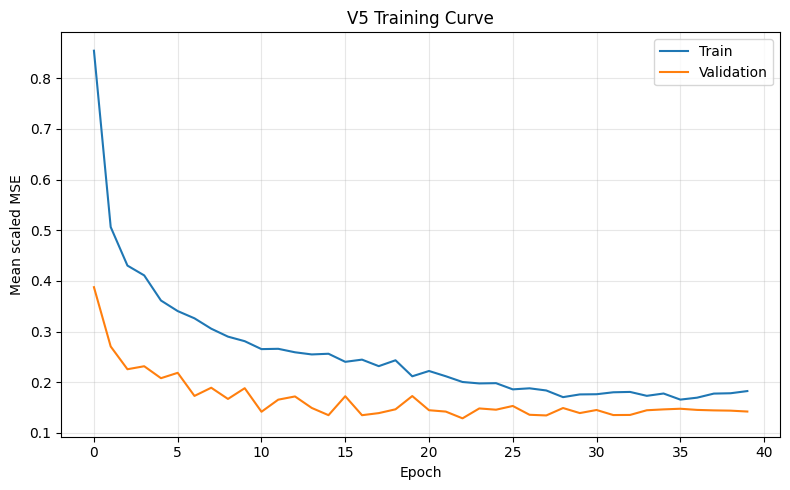

Held-out test metrics (original target units):


,target,MAE,RMSE,R2
0,formation_energy,0.456953,0.705663,0.501648
1,band_gap,0.695938,1.122328,0.579286
2,energy_above_hull,0.018345,0.026431,0.000000


In [12]:
# [셀의 목적]
# AdamW 최적화기로 모델 파라미터를 갱신하고 validation loss가 가장 낮은 체크포인트를 저장합니다.
# MSELoss는 스케일링된 세 타깃의 예측 오차 제곱을 계산합니다.
# run_epoch는 train=True일 때만 역전파와 optimizer.step을 수행하고, 평가 시에는 gradient 계산을 끕니다.
# Gradient clipping은 기울기 노름이 1.0을 넘을 때 크기를 제한해 학습 불안정을 줄입니다.
# CosineAnnealingLR은 epoch가 진행됨에 따라 학습률을 코사인 곡선 형태로 낮춥니다.
# 매 epoch마다 train/validation loss를 기록하고 validation loss가 개선되면 모델 상태를 저장합니다.
# 저장된 체크포인트에는 모델 가중치, 타깃 스케일러, epoch, 검증 손실, 모델 설정, 타깃 목록, 시드가 포함됩니다.
# 학습 곡선은 output/training_curve_v5.png로 저장됩니다.
# 마지막에는 가장 좋은 validation 체크포인트를 복원하고 test set에서 예측합니다.
# inverse_transform으로 예측값과 정답을 원래 단위로 되돌린 뒤 타깃별 MAE, RMSE, R²를 계산합니다.
# [해석] MAE/RMSE가 작을수록 오차가 작고, R²는 표본·타깃 분산에 따라 음수가 될 수도 있습니다.
# [주의] 코드를 실행하지 않은 상태에서 학습 성공이나 특정 성능 수치를 주장할 수 없습니다.

# 10. 학습 루프 — Edge 전달, 체크포인트 재현성, 최종 테스트 평가
optimizer=torch.optim.AdamW(model.parameters(),lr=3e-4,weight_decay=1e-4)
EPOCHS=40
scheduler=CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-6)
criterion=nn.MSELoss()

 # train=True면 가중치를 업데이트하고, False면 평가 손실만 계산한다.
def run_epoch(loader,train=True):
    model.train() if train else model.eval(); total_loss=0.0; n_batches=0
    with torch.set_grad_enabled(train):
        for atoms,feats,targets,formulas,mask,mids,edges in loader:
            atoms=atoms.to(device); feats=feats.to(device); targets=targets.to(device); mask=mask.to(device)
            preds,_=model(atoms,feats,key_padding_mask=mask,edges=edges)
            loss=sum(criterion(preds[name].squeeze(-1),targets[:,i]) for i,name in enumerate(TARGET_COLS))/len(TARGET_COLS)
            if train:
                optimizer.zero_grad(set_to_none=True); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            total_loss+=float(loss.detach().cpu()); n_batches+=1
    return total_loss/max(n_batches,1)

best_val=float('inf'); history={'train':[],'val':[]}
print('[Training Start]')
 # 매 epoch마다 train/validation을 평가하고 가장 좋은 validation 체크포인트를 보존한다.
for epoch in range(1,EPOCHS+1):
    tr=run_epoch(train_loader,True); va=run_epoch(val_loader,False); scheduler.step()
    history['train'].append(tr); history['val'].append(va); mark=''
    if va<best_val:
        best_val=va
        torch.save({'model_state_dict':model.state_dict(),'target_scaler':target_scaler,
            'epoch':epoch,'val_loss':va,'model_config':{'d_model':128,'depth':4,'nhead':4,
            'dropout':0.15,'n_element_features':N_ELEMENT_FEATURES},
            'target_cols':TARGET_COLS,'seed':SEED},
            os.path.join(OUTPUT_DIR,'graphene_materials_transformer_v5.pt'))
        mark=' *Best'
    print(f'Epoch {epoch:02d} | Train {tr:.5f} | Val {va:.5f} | LR {scheduler.get_last_lr()[0]:.2e}{mark}')
print(f'Best validation loss (scaled-target MSE): {best_val:.5f}')
plt.figure(figsize=(8,5)); plt.plot(history['train'],label='Train'); plt.plot(history['val'],label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Mean scaled MSE'); plt.legend(); plt.grid(alpha=.3); plt.title('V5 Training Curve')
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR,'training_curve_v5.png'),dpi=150); plt.show()

# best checkpoint 복원 후 완전히 분리한 test set의 타깃별 MAE/RMSE/R² 평가
ckpt=torch.load(os.path.join(OUTPUT_DIR,'graphene_materials_transformer_v5.pt'),map_location=device,weights_only=False)
model.load_state_dict(ckpt['model_state_dict']); target_scaler=ckpt['target_scaler']; model.eval()
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
all_y=[]; all_pred=[]
with torch.no_grad():
    for atoms,feats,targets,formulas,mask,mids,edges in test_loader:
        atoms=atoms.to(device); feats=feats.to(device); mask=mask.to(device)
        preds,_=model(atoms,feats,key_padding_mask=mask,edges=edges)
        all_pred.append(torch.cat([preds[n] for n in TARGET_COLS],dim=1).cpu().numpy())
        all_y.append(targets.numpy())
y_scaled=np.vstack(all_y); p_scaled=np.vstack(all_pred)
y_true=target_scaler.inverse_transform(y_scaled); y_pred=target_scaler.inverse_transform(p_scaled)
metric_rows=[]
 # 물성마다 원래 단위 기준 오차를 별도로 계산해 서로 다른 물성의 성능을 구분한다.
for j,name in enumerate(TARGET_COLS):
    metric_rows.append({'target':name,'MAE':mean_absolute_error(y_true[:,j],y_pred[:,j]),
        'RMSE':mean_squared_error(y_true[:,j],y_pred[:,j])**0.5,
        'R2':r2_score(y_true[:,j],y_pred[:,j]) if len(y_true)>1 else np.nan})
metrics_df=pd.DataFrame(metric_rows); metrics_df.to_csv(os.path.join(OUTPUT_DIR,'test_metrics_v5.csv'),index=False)
print('Held-out test metrics (original target units):'); display(metrics_df)


## 11. 독립 기준모형: Random Forest / Extra Trees / 검증셋 기반 앙상블

Transformer가 유일한 모델이 되지 않도록, 조성·CrystalNN 구조 요약값으로 학습하는 두 개의 트리 기준모형을 함께 평가합니다. 스케일러/모델 선택은 train/validation만 사용하고, 최종 지표는 test set에서 한 번 계산합니다. 이 기준모형은 원자별 그래프를 직접 읽지 않으므로 Transformer와 입력 표현이 다릅니다.

검증셋 MAE로 앙상블 가중치를 산정하고 테스트셋의 MAE/RMSE/R²를 CSV로 저장합니다. 표본이 적거나 물질 계열이 겹치면 일반화 성능이 과대평가될 수 있으므로, 후속 연구에서는 조성/구조군 단위의 group split도 권장됩니다.

In [13]:
# [셀의 목적]
# Transformer와 비교하기 위해 표 형식 descriptor를 입력으로 하는 두 기준모형을 학습합니다.
# Random Forest는 여러 결정 트리를 부트스트랩 표본/무작위 피처로 학습해 평균을 냅니다.
# Extra Trees는 분할 기준을 더 무작위화한 트리 앙상블입니다.
# BASE_FEATURES에는 조성 요약과 구조 descriptor만 넣고 식별자나 타깃값은 제외합니다.
# 결측치와 무한대는 train 데이터에서 계산한 중앙값으로 대체해 검증/테스트 통계가 누수되지 않게 합니다.
# 각 모델은 세 타깃을 동시에 출력하는 multi-output 회귀기로 학습됩니다.
# validation의 평균 타깃 MAE가 낮은 모델에 더 큰 역오차 가중치를 주어 앙상블 예측을 만듭니다.
# 앙상블 가중치는 validation 성능으로만 정하고 test 정답을 사용하지 않습니다.
# 마지막에 test set의 타깃별 MAE/RMSE/R²를 계산하고 CSV/JSON으로 결과와 설정을 저장합니다.
# [공정 비교의 한계] 기준모형은 요약 descriptor를, Transformer는 원자 토큰과 간선을 사용하므로 입력 정보가 다릅니다.
# 성능 차이는 아키텍처만의 효과가 아니라 입력 표현·전처리·모델 복잡도 차이도 반영합니다.

# 11. Tabular baseline models + validation-weighted ensemble benchmark
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 조성 및 구조 descriptor만 사용하는 tabular baseline.
# 식별자, formula, 원시 구조 딕셔너리, 타깃값은 입력 피처에서 제외합니다.
BASE_FEATURES = [
    'n_atoms','z_mean','z_std','carbon_ratio','group14_ratio','metal_ratio','n_unique_elements',
    'n_sites','mean_coordination_number','std_coordination_number','mean_bond_length',
    'std_bond_length','mean_bond_angle','std_bond_angle','estimated_dimensionality',
    'carbon_fraction','three_coordinate_fraction','carbon_three_coordinate_fraction',
    'carbon_sp2_angle_deviation','cc_bond_length_deviation'
]
BASE_FEATURES = [c for c in BASE_FEATURES if c in df.columns]
if len(BASE_FEATURES) < 5:
    raise ValueError(f'Not enough tabular features for baseline comparison: {BASE_FEATURES}')

 # 기준모형 입력 X와 세 타깃 y를 분리해 NumPy 배열로 반환한다.
def _xy(frame):
    X = frame[BASE_FEATURES].replace([np.inf,-np.inf],np.nan)
    # Imputation medians are computed on training data only (defined below).
    X = X.fillna(train_medians)
    y = frame[TARGET_COLS].to_numpy(dtype=float)
    return X.to_numpy(dtype=float), y

train_medians = df.loc[train_df.index, BASE_FEATURES].replace([np.inf,-np.inf],np.nan).median().fillna(0.0)
X_train, y_train = _xy(train_df)
X_val, y_val = _xy(val_df)
X_test, y_test = _xy(test_df)

baseline_models = {
    'RandomForest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1)
}
val_preds, test_preds, baseline_rows = {}, {}, []
 # 각 트리 앙상블을 train에서 학습하고 validation/test 예측을 따로 저장한다.
for model_name, estimator in baseline_models.items():
    estimator.fit(X_train, y_train)
    pv = estimator.predict(X_val)
    pt = estimator.predict(X_test)
    val_preds[model_name] = pv
    test_preds[model_name] = pt
    baseline_rows.append({
        'model': model_name,
        'validation_macro_MAE': float(np.mean([mean_absolute_error(y_val[:,j], pv[:,j]) for j in range(len(TARGET_COLS))]))
    })

# Validation MAE inverse weighting; no test labels are used to choose weights.
 # 검증셋의 평균 MAE를 기준으로 역오차 가중치를 산출한다. test 정답은 사용하지 않는다.
val_mae = {name: row['validation_macro_MAE'] for name,row in zip(baseline_models.keys(), baseline_rows)}
inv = {name: 1.0/max(err, 1e-8) for name,err in val_mae.items()}
weight_sum = sum(inv.values())
ensemble_weights = {name: value/weight_sum for name,value in inv.items()}
ensemble_test = sum(ensemble_weights[name]*test_preds[name] for name in baseline_models)

all_test_predictions = {**test_preds, 'ValidationWeightedEnsemble': ensemble_test}
metric_rows = []
for model_name, prediction in all_test_predictions.items():
    for j,target in enumerate(TARGET_COLS):
        metric_rows.append({
            'model': model_name, 'target': target,
            'MAE': float(mean_absolute_error(y_test[:,j], prediction[:,j])),
            'RMSE': float(mean_squared_error(y_test[:,j], prediction[:,j])**0.5),
            'R2': float(r2_score(y_test[:,j], prediction[:,j])) if len(y_test)>1 else np.nan,
            'validation_macro_MAE': val_mae.get(model_name, np.nan),
            'ensemble_weight': ensemble_weights.get(model_name, np.nan)
        })
benchmark_df = pd.DataFrame(metric_rows)
benchmark_path = os.path.join(OUTPUT_DIR, 'baseline_ensemble_test_metrics_v5.csv')
benchmark_df.to_csv(benchmark_path, index=False)
with open(os.path.join(OUTPUT_DIR, 'baseline_ensemble_config_v5.json'),'w') as f:
    json.dump({'features':BASE_FEATURES,'target_cols':TARGET_COLS,
               'validation_macro_mae':val_mae,'ensemble_weights':ensemble_weights,
               'note':'Weights selected using validation MAE only; test set used for final reporting.'}, f, indent=2)
print('Validation MAE by baseline:', val_mae)
print('Validation-derived ensemble weights:', ensemble_weights)
print('Held-out test metrics saved to:', benchmark_path)
display(benchmark_df)


Validation MAE by baseline: {'RandomForest': 0.3417762045670545, 'ExtraTrees': 0.34158419431154746}
Validation-derived ensemble weights: {'RandomForest': 0.4998595102556263, 'ExtraTrees': 0.5001404897443736}
Held-out test metrics saved to: output/baseline_ensemble_test_metrics_v5.csv


,model,target,MAE,RMSE,R2,validation_macro_MAE,ensemble_weight
0,RandomForest,formation_energy,0.559399,0.757262,0.426103,0.341776,0.49986
1,RandomForest,band_gap,0.738585,1.075707,0.613512,0.341776,0.49986
2,RandomForest,energy_above_hull,0.000000,0.000000,1.000000,0.341776,0.49986
3,ExtraTrees,formation_energy,0.523821,0.715849,0.487158,0.341584,0.50014
4,ExtraTrees,band_gap,0.712392,1.082196,0.608836,0.341584,0.50014
5,ExtraTrees,energy_above_hull,0.000000,0.000000,1.000000,0.341584,0.50014
6,ValidationWeightedEnsemble,formation_energy,0.539461,0.729688,0.467136,NaN,NaN
7,ValidationWeightedEnsemble,band_gap,0.716184,1.065164,0.621051,NaN,NaN
8,ValidationWeightedEnsemble,energy_above_hull,0.000000,0.000000,1.000000,NaN,NaN


## Transformer 출력을 이용한 그래핀-like 스크리닝

학습된 Transformer는 각 물질에 대해:
1. **물성 예측값** (formation energy, band gap, Ehull)
2. **임베딩 벡터** (Attention Pooling 결과, 128차원)

을 반환한다.

그래핀 점수는 예측 물성 + 조성/구조 피처(탄소 비율, 3배위 분율, C–C 결합 길이 편차 등)를 가중합하여 계산하고 랭킹한다.
임베딩은 PCA로 2D 투영하여 유사 물질 군집을 시각화한다.

In [14]:
# [셀의 목적]
# 가장 좋은 Transformer 체크포인트를 불러와 데이터 전체의 물성을 예측하고 그래핀 유사 후보를 우선순위화합니다.
# predict_all은 Dataset/DataLoader를 통해 배치 추론을 수행하며, 학습 시와 같은 토큰/edge 경로를 사용합니다.
# 모델 출력은 타깃 스케일 공간에 있으므로 target_scaler.inverse_transform으로 원래 단위로 되돌립니다.
# 예측 결과와 조성·구조 descriptor를 material_id 및 formula로 병합합니다.
# graphene_score는 탄소/14족 비율, 3배위, 결합각 편차, C–C 거리 편차, hull 예측, 차원성, 밴드갭을 조합한 휴리스틱 점수입니다.
# 점수 가중치는 물리 법칙으로 학습된 값이나 검증된 확률이 아니라 연구자가 설정한 우선순위 규칙입니다.
# energy_above_hull 음수 예측은 0으로 자르며, 이는 점수 계산에서 비현실적 음수값이 보상되지 않게 하려는 처리입니다.
# 예측 밴드갭 범위 0~2.5 eV와 2차원 차원성에 보너스를 주지만, 이는 탐색 기준이지 합성 가능성 판정이 아닙니다.
# 결과 전체와 상위 50개 후보를 각각 CSV로 저장합니다.
# [주의] 후보 순위는 DFT 계산, 열역학적 안정성 확인, 구조 relaxation 또는 실험 검증을 대체하지 않습니다.

# 11. 그래핀 유사 후보 스크리닝 + 랭킹 — 실제 Edge 기반 추론
ckpt=torch.load(os.path.join(OUTPUT_DIR,'graphene_materials_transformer_v5.pt'),map_location=device,weights_only=False)
model.load_state_dict(ckpt['model_state_dict']); target_scaler=ckpt['target_scaler']; model.eval()

 # 입력 데이터 전체를 배치 단위로 추론하여 예측값과 임베딩을 표로 만든다.
def predict_all(df_in,edge_dict):
    ds=RealMaterialDatasetV5(df_in,edge_dict)
    loader=DataLoader(ds,batch_size=16,shuffle=False,collate_fn=collate_fn_v5)
    rows=[]
    with torch.no_grad():
        for atoms,feats,targets,formulas,mask,mids,edges in loader:
            atoms=atoms.to(device); feats=feats.to(device); mask=mask.to(device)
            preds,emb=model(atoms,feats,key_padding_mask=mask,edges=edges)
            matrix=torch.cat([preds[n] for n in TARGET_COLS],dim=1).cpu().numpy()
            emb=emb.cpu().numpy()
            for i,mid in enumerate(mids):
                rows.append({'material_id':mid,'formula':formulas[i],
                    'pred_formation_energy_scaled':matrix[i,0], 'pred_band_gap_scaled':matrix[i,1],
                    'pred_energy_above_hull_scaled':matrix[i,2], 'embedding':emb[i].tolist()})
    return pd.DataFrame(rows)

pred_df=predict_all(df,edge_dict)
pred_df[['pred_formation_energy','pred_band_gap','pred_energy_above_hull']]=target_scaler.inverse_transform(
    pred_df[['pred_formation_energy_scaled','pred_band_gap_scaled','pred_energy_above_hull_scaled']].to_numpy())
merge_cols=['material_id','formula','carbon_ratio','group14_ratio','three_coordinate_fraction',
            'carbon_three_coordinate_fraction','carbon_three_coordinate_count','carbon_sp2_angle_deviation',
            'cc_bond_length_deviation','mean_coordination_number','mean_bond_angle','carbon_fraction',
            'estimated_dimensionality','formation_energy','band_gap','energy_above_hull']
pred_df=pred_df.merge(df[merge_cols].drop_duplicates('material_id'),on=['material_id','formula'],how='left',validate='many_to_one')

 # 여러 지표를 하나의 후보 우선순위 점수로 합치는 경험적 규칙이다.
def graphene_score(row):
    """휴리스틱 우선순위 점수이며, 검증된 그래핀 유사성 확률은 아닙니다."""
    carbon=float(row.get('carbon_ratio',0) or 0)
    group14=float(row.get('group14_ratio',0) or 0)
    three=float(row.get('three_coordinate_fraction',0) or 0)
    carbon_three=float(row.get('carbon_three_coordinate_fraction',0) or 0)
    angle_dev=float(row.get('carbon_sp2_angle_deviation',60) or 60)
    ccdev=float(row.get('cc_bond_length_deviation',1) or 1)
    dim=float(row.get('estimated_dimensionality',0) or 0)
    # E_hull 물리량은 0 이상으로 해석. 음수 예측은 보상하지 않고 0으로 클립.
    eh=max(0.0,float(row.get('pred_energy_above_hull',1.0)))
    bg=float(row.get('pred_band_gap',10.0))
    score=2.0*carbon + 1.0*group14 + 1.0*three + 1.5*carbon_three
    score += max(0.0,1.0-min(ccdev,1.0))
    # Carbon-centered angle closeness to ideal 120° is a geometric proxy, not proof of sp² hybridization.
    score += max(0.0, 1.0-min(angle_dev/30.0, 1.0)) if carbon>0 else 0.0
    score += float(np.exp(-eh/0.1))  # 안정성 예측이 0에 가까울수록 높은 점수
    score += 0.75 if dim==2 else 0.0
    score += 0.25 if 0.0<=bg<=2.5 else 0.0
    return float(score)

 # 각 행에 점수 함수를 적용하고 높은 점수부터 정렬한다.
pred_df['graphene_score']=pred_df.apply(graphene_score,axis=1)
pred_df['screening_note']='Heuristic ranking only; not experimental validation or DFT confirmation'
pred_df=pred_df.sort_values('graphene_score',ascending=False).reset_index(drop=True)
pred_df.to_csv(os.path.join(OUTPUT_DIR,'materials_with_graphene_scores_v5.csv'),index=False)
top_candidates=pred_df.head(50)
top_candidates.to_csv(os.path.join(OUTPUT_DIR,'graphene_like_candidates_ranked_v5.csv'),index=False)
print('Top 10 heuristic candidates:')
print(top_candidates[['material_id','formula','graphene_score','pred_formation_energy','pred_band_gap',
                      'pred_energy_above_hull','estimated_dimensionality','carbon_ratio',
                      'three_coordinate_fraction']].head(10).to_string(index=False))


Dataset size: 500
Top 10 heuristic candidates:
material_id     formula  graphene_score  pred_formation_energy  pred_band_gap  pred_energy_above_hull  estimated_dimensionality  carbon_ratio  three_coordinate_fraction
    mp-4691      Ag2CO3        4.242140              -1.696225       1.233877                0.001710                         0      0.166667                   0.333333
 mp-1029975   Al2(CN2)3        2.285683              -0.618217       1.919937                0.062421                         0      0.375000                   0.375000
  mp-561620     Ag3AsS3        2.250000              -0.661348       0.665727               -0.018220                         0      0.000000                   1.000000
  mp-552185       AgNO3        2.050000              -1.276264       0.643097               -0.013131                         0      0.000000                   0.800000
    mp-9956      AlCr2C        2.039307              -0.168736      -0.013261                0.023660       

## 후속 검증 프로토콜: 후보를 '그래핀'으로 확정하기 전에

AI 순위는 DFT 검증 대상을 고르는 도구입니다. Al₂(CN₂)₃에 대해 사용자가 보고한 값(formation = −0.249, hull = 0.03, band gap = 0.0329)은 현재 대화에서 보고된 모델 출력이며, 이 노트북에서 재계산/독립 검증된 결과가 아닙니다.

1. **구조 확인:** CIF/원자 좌표, 조성, 원자수, 주기경계, 층상 구조와 진공층을 검토합니다.
2. **Relaxation:** 동일한 교환-상관 함수, pseudopotential, cutoff, k-point 수렴 기준으로 구조 최적화합니다.
3. **안정성:** formation energy와 convex-hull distance를 동일한 reference phase 기준으로 다시 계산합니다. `energy above hull`은 보통 0에 가까울수록 열역학적으로 유리하지만, kinetic stability/합성 가능성을 보장하지 않습니다.
4. **전자구조:** band structure와 DOS를 계산합니다. 그래핀 유사 Dirac 물성을 주장하려면 K점 부근의 선형 분산, Dirac crossing, Fermi velocity, 밴드 점유를 확인해야 합니다. 작은 band gap 숫자만으로 Dirac cone을 증명할 수 없습니다.
5. **동역학/열 안정성:** phonon dispersion에서 imaginary modes를 점검하고, 필요하면 ab-initio MD 및 substrate/strain 영향도 평가합니다.
6. **2D성:** 층간 진공 수렴, exfoliation/formation energetics, in-plane elastic/mechanical stability를 확인합니다.
7. **비교군:** graphene과 BC₂N 등 비교 구조에 대해 같은 계산 설정을 적용합니다.

이 프로토콜은 실행 설계이며, 이 노트북에서 Quantum ESPRESSO/DFT 계산이 자동 실행되거나 검증 완료되었다는 뜻은 아닙니다.

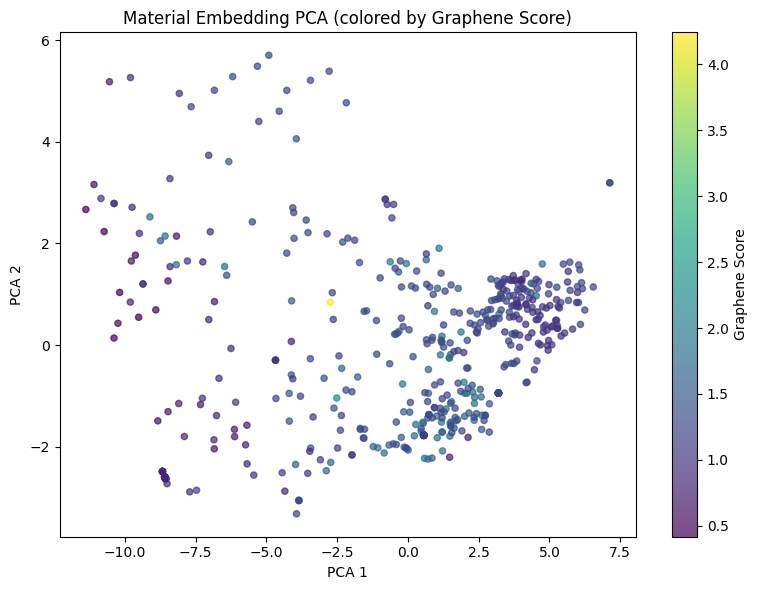

PCA saved.


In [15]:
# [셀의 목적]
# Transformer가 반환한 128차원 pooled embedding을 PCA로 2차원으로 투영합니다.
# PCA는 데이터의 분산을 설명하는 선형 축을 찾는 차원 축소 기법입니다.
# pca1/pca2는 시각화를 위한 좌표이며 특정 화학 결합이나 물리량 그 자체를 뜻하지 않습니다.
# 점의 색은 휴리스틱 graphene_score를 나타내어 고득점 후보가 어느 영역에 놓이는지 탐색하게 합니다.
# PNG와 material_id/formula/PCA 좌표/점수를 담은 CSV를 output 폴더에 저장합니다.
# [주의] PCA에서 가까운 두 점이 반드시 구조적으로 동형이거나 물성이 같다는 뜻은 아닙니다.

# 12. Transformer 임베딩 PCA 시각화
# PCA는 128차원 표현을 2차원으로 압축한 탐색용 그림이며, 축 자체에 물리적 의미가 보장되지는 않습니다.
# 모델이 학습한 128차원의 화학적 특징 표상을 2차원(PCA) 평면 공간에 뿌려 관계 분석
 # 행마다 저장된 임베딩 리스트를 동일한 길이의 2D 행렬로 쌓는다.
emb_matrix = np.stack(pred_df['embedding'].values)
pca = PCA(n_components=2, random_state=SEED)
 # 128차원 표현을 분산이 큰 두 개의 주성분 축으로 투영한다.
emb_2d = pca.fit_transform(emb_matrix)
pred_df['pca1'] = emb_2d[:,0]
pred_df['pca2'] = emb_2d[:,1]

# 시각화 매핑 플롯
plt.figure(figsize=(8,6))
sc = plt.scatter(pred_df['pca1'], pred_df['pca2'], c=pred_df['graphene_score'],
                 cmap='viridis', s=20, alpha=0.7)
plt.colorbar(sc, label='Graphene Score')
plt.xlabel('PCA 1'); plt.ylabel('PCA 2')
plt.title('Material Embedding PCA (colored by Graphene Score)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'graphene_embedding_pca_v5.png'), dpi=150)
plt.show()

pred_df[['material_id','formula','pca1','pca2','graphene_score']].to_csv(
    os.path.join(OUTPUT_DIR, 'graphene_embedding_pca_v5.csv'), index=False)
print('PCA saved.')

In [16]:
# [셀의 목적]
# Streamlit 앱의 전체 Python 소스코드를 문자열(app_code)로 정의한 뒤 app.py 파일로 저장합니다.
# 앱은 앞 단계에서 생성한 점수 CSV, 상위 후보 CSV, PCA CSV를 읽어 표와 대화형 산점도를 표시합니다.
# st.cache_data는 CSV를 매번 다시 읽지 않도록 데이터 로드를 캐시합니다.
# 사이드바 슬라이더는 점수 하한, 밴드갭 상한, 탄소 비율 하한을 지정하는 사용자 필터입니다.
# 필터는 이미 계산된 결과를 보여주는 기능이며 대시보드 안에서 모델을 재학습하지 않습니다.
# Plotly 산점도는 PCA 좌표를 표시하고 점 위에 마우스를 올리면 물질 식을 확인하도록 구성됩니다.
# 앱에서 데이터 로드에 실패하면 오류를 표시하고 실행을 중단합니다.
# 마지막으로 CSV들을 앱 디렉터리와 하위 output 폴더에 복사해 앱이 파일을 찾도록 준비합니다.
# [주의] 이 셀은 앱 파일을 생성할 뿐, Streamlit이 정상 구동하거나 외부에서 접속 가능함을 보장하지 않습니다.

# 13. Streamlit 대시보드 생성 소스코드 문자열 정의 및 파일 쓰기
 # 아래 문자열은 별도의 app.py 파일에 저장될 Streamlit 애플리케이션 코드다.
app_code = r'''
# Streamlit UI 프레임워크: 슬라이더·표·차트를 웹 페이지에 표시한다.
import streamlit as st
import pandas as pd
import plotly.express as px
import os
from pathlib import Path
BASE_DIR = Path(__file__).resolve().parent
OUTPUT_DIR = BASE_DIR / "output"

st.set_page_config(page_title="Graphene Materials Transformer V5", layout="wide")
st.title("𛗳 Graphene Materials Transformer V5")
st.markdown("ComFormer-style Transformer for Graphene-like Material Screening")

@st.cache_data
 # CSV를 읽어 화면 표·산점도에서 재사용할 데이터프레임을 반환한다.
# 결과 CSV 세 개를 읽는다. 모델 학습이나 API 요청은 이 앱에서 수행하지 않는다.
def load_data():
    base = OUTPUT_DIR
    scores = pd.read_csv(os.path.join(base, "materials_with_graphene_scores_v5.csv"))
    ranked = pd.read_csv(os.path.join(base, "graphene_like_candidates_ranked_v5.csv"))
    pca_df = pd.read_csv(os.path.join(base, "graphene_embedding_pca_v5.csv"))
    return scores, ranked, pca_df

try:
    scores, ranked, pca_df = load_data()
except Exception as e:
    st.error(f"데이터 로드 실패: {e}")
    st.stop()

# 사이드바는 화면에 표시할 후보를 좁히는 필터 UI를 제공한다.
st.sidebar.header("Filters")
min_score = st.sidebar.slider("Min Graphene Score", 0.0, max(float(scores["graphene_score"].max()), 0.01), 0.0)
max_bg = st.sidebar.slider("Max Band Gap (eV)", 0.0, 8.0, 3.0)
min_carbon = st.sidebar.slider("Min Carbon Ratio", 0.0, 1.0, 0.0)

 # 사용자가 선택한 세 조건을 모두 만족하는 후보만 표시한다.
# 선택된 조건을 모두 만족하는 행만 filtered 데이터프레임에 남긴다.
filtered = scores[
    (scores["graphene_score" ]>= min_score) &
    (scores["pred_band_gap"] <= max_bg) &
    (scores["carbon_ratio"] >= min_carbon)
].copy()

st.subheader(f"Filtered Candidates: {len(filtered)}")
st.dataframe(
    filtered[["formula","graphene_score","pred_formation_energy","pred_band_gap",
              "pred_energy_above_hull","carbon_ratio","three_coordinate_fraction","carbon_three_coordinate_fraction"]].head(100),
    use_container_width=True
)

# PCA는 모델 임베딩을 2차원으로 표시한 탐색 그림이며 물리 좌표가 아니다.
st.subheader("Embedding PCA")
fig = px.scatter(pca_df, x="pca1", y="pca2", color="graphene_score",
                 hover_data=["formula"], color_continuous_scale="Viridis",
                 title="Material Embedding Space")
st.plotly_chart(fig, use_container_width=True)

st.subheader("Top 20 Graphene-like Materials")
st.dataframe(ranked.head(20)[["formula","graphene_score","pred_formation_energy",
                              "pred_band_gap","carbon_ratio","three_coordinate_fraction","carbon_three_coordinate_fraction"]],
             use_container_width=True)

st.markdown("---")
st.caption("Heuristic screening only; predictions require independent validation and do not replace DFT/experimental confirmation.")
'''

# 앱 디렉토리에 app.py 파일 생성 저장
with open(os.path.join(APP_DIR, 'app.py'), 'w') as f:
    f.write(app_code)

# 연산 결과 데이터를 스트림릿 웹 앱 경로로 복사 전송
for fn in ['materials_with_graphene_scores_v5.csv',
           'graphene_like_candidates_ranked_v5.csv',
           'graphene_embedding_pca_v5.csv']:
    src = os.path.join(OUTPUT_DIR, fn)
    if os.path.exists(src):
        shutil.copy(src, os.path.join(APP_DIR, fn))

os.makedirs(os.path.join(APP_DIR, 'output'), exist_ok=True)
for fn in os.listdir(OUTPUT_DIR):
    s = os.path.join(OUTPUT_DIR, fn)
    d = os.path.join(APP_DIR, 'output', fn)
    if os.path.isfile(s):
        shutil.copy(s, d)

print('Streamlit app files updated.')

Streamlit app files updated.


In [17]:
# [셀의 목적]
# 로컬 Streamlit 서버를 시작하고 HTTP 응답을 확인한 다음 임시 Cloudflare Tunnel URL을 찾습니다.
# subprocess.Popen은 별도 프로세스로 서버를 띄우므로 노트북 셀 자체가 서버 프로세스를 직접 실행하지 않습니다.
# wait_for_http는 제한 시간 동안 localhost:8501의 HTTP 200 응답을 확인합니다.
# 응답이 없거나 프로세스가 종료되면 로그 파일을 확인하도록 안내합니다.
# cloudflared 실행 파일이 없으면 공식 GitHub 릴리스 주소에서 바이너리를 내려받으려 시도합니다.
# 터널 로그에서 trycloudflare.com 주소 형태를 정규식으로 찾고, 발견 시 대시보드 링크를 출력합니다.
# 임시 터널은 공개 접속 주소를 만들 수 있으므로 민감한 데이터나 비밀 정보를 앱에 넣지 마십시오.
# [주의] 다운로드/네트워크/실행 권한/Colab 런타임 정책에 따라 터널이 실패할 수 있습니다.
# URL이 출력되지 않으면 성공한 것으로 간주하지 말고 Streamlit 및 cloudflared 로그를 확인하십시오.

# 14. Streamlit 실행 + Cloudflare Tunnel — 로그와 준비 상태 확인
import urllib.request
streamlit_log=os.path.join(OUTPUT_DIR,'streamlit.log')
streamlit_log_handle=open(streamlit_log,'w')
streamlit_proc=subprocess.Popen(['streamlit','run',os.path.join(APP_DIR,'app.py'),
    '--server.port','8501','--server.headless','true'],stdout=streamlit_log_handle,
    stderr=subprocess.STDOUT)

 # 서버가 실제로 HTTP 응답을 하는지 제한 시간 동안 반복 확인한다.
def wait_for_http(url,timeout=45):
    deadline=time.time()+timeout
    while time.time()<deadline:
        if streamlit_proc.poll() is not None:
            raise RuntimeError(f'Streamlit exited. Inspect {streamlit_log}')
        try:
            with urllib.request.urlopen(url,timeout=2) as response:
                if response.status==200: return True
        except Exception:
            time.sleep(1)
    return False

if wait_for_http('http://127.0.0.1:8501',timeout=45):
    print('Streamlit local health check: HTTP 200')
else:
    print(f'Streamlit did not respond. Inspect log: {streamlit_log}')
    print(open(streamlit_log,errors='ignore').read()[-4000:])

CLOUDFLARED='/usr/local/bin/cloudflared'
 # 터널 프로그램이 없으면 내려받기를 시도한다. 네트워크 정책에 따라 실패할 수 있다.
if not os.path.exists(CLOUDFLARED):
    import urllib.request as _urlreq
    url='https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64'
    try:
        _urlreq.urlretrieve(url,CLOUDFLARED); os.chmod(CLOUDFLARED,0o755)
    except Exception as exc:
        print('Cloudflare binary download failed:',repr(exc))

public_url=None
tunnel_log=os.path.join(OUTPUT_DIR,'cloudflared.log')
if os.path.exists(CLOUDFLARED) and streamlit_proc.poll() is None:
    tunnel_log_handle=open(tunnel_log,'w')
    tunnel_proc=subprocess.Popen([CLOUDFLARED,'tunnel','--url','http://127.0.0.1:8501','--no-autoupdate'],
        stdout=tunnel_log_handle,stderr=subprocess.STDOUT)
    for _ in range(30):
        time.sleep(2)
        try:
            log_text=open(tunnel_log,encoding='utf-8',errors='ignore').read()
        except OSError:
            log_text=''
        match=re.search(r'https://[a-zA-Z0-9-]+\.trycloudflare\.com',log_text)
        if match:
            public_url=match.group(0); break
 # 로그에서 공개 URL을 실제로 찾은 경우에만 링크를 출력한다.
if public_url:
    with open(os.path.join(APP_DIR,'public_url.txt'),'w') as f: f.write(public_url)
    from IPython.display import display,HTML
    display(HTML(f'<h3>Graphene Materials Transformer V5</h3><p><a href="{public_url}" target="_blank">Open dashboard</a></p><p>{public_url}</p>'))
else:
    print('Public tunnel URL not confirmed. Check:',tunnel_log)
    if os.path.exists(tunnel_log): print(open(tunnel_log,errors='ignore').read()[-4000:])


Streamlit local health check: HTTP 200


In [18]:
# [셀의 목적]
# Colab 환경에서 핵심 산출물 파일을 사용자의 브라우저로 다운로드하도록 요청합니다.
# 모델 체크포인트(.pt), 후보 순위 CSV, 전체 점수 CSV, PCA 좌표 CSV, 그림 PNG가 대상입니다.
# 파일이 존재할 때만 다운로드를 시도하고, 누락된 파일은 Not found로 표시합니다.
# google.colab 모듈이 없으면 로컬 환경으로 간주하고 결과 폴더의 절대 경로를 안내합니다.
# 이 셀의 마지막 메시지는 파이프라인 셀 실행이 끝났다는 안내일 뿐 과학적 타당성이나 배포 성공을 증명하지 않습니다.
# 실제로 생성된 파일과 평가 지표를 확인하고, DFT 또는 실험으로 후보를 별도 검증해야 합니다.

# 15. 결과 파일 다운로드 (Colab 브라우저 트리거)
try:
    from google.colab import files
    key_files = [
        'graphene_materials_transformer_v5.pt',
        'graphene_like_candidates_ranked_v5.csv',
        'materials_with_graphene_scores_v5.csv',
        'graphene_embedding_pca_v5.csv',
        'training_curve_v5.png',
        'graphene_embedding_pca_v5.png'
    ]
    # 추출 및 저장 완료된 핵심 데이터셋 및 모델 가중치 파일 다운로드
        # 파일마다 존재 여부를 확인한 후 브라우저 다운로드를 요청한다.
    for fn in key_files:
        p = os.path.join(OUTPUT_DIR, fn)
        if os.path.exists(p):
            print(f'Downloading: {fn}')
            files.download(p)
        else:
            print(f'Not found: {fn}')
except ImportError:
    print('Not in Colab. Files are in:', os.path.abspath(OUTPUT_DIR))

print('\nPipeline cells finished. Review test_metrics_v5.csv and logs; this message alone is not proof of scientific validity or successful public deployment.')

Downloading: graphene_materials_transformer_v5.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: graphene_like_candidates_ranked_v5.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloading: graphene_embedding_pca_v5.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Pipeline cells finished. Review test_metrics_v5.csv and logs; this message alone is not proof of scientific validity or successful public deployment.
